In [32]:
# pushing the files into githhub
from pathlib import Path

print(Path.cwd())
print(list(Path.cwd().glob("*.ipynb")))

C:\Users\TechNest Computer#\Documents\my projects\EEP
[WindowsPath('C:/Users/TechNest Computer#/Documents/my projects/EEP/okay cell.ipynb')]


In [41]:
%cd "C:\Users\TechNest Computer#\Documents\my projects\EEP"
!git init
!git add "okay cell.ipynb"
!git commit -m "Add okay cell notebook"
!git remote -v
!git remote add origin https://github.com/MELES-DS/EEP.git
!git branch -M main
!git push -u origin main

C:\Users\TechNest Computer#\Documents\my projects\EEP
Reinitialized existing Git repository in C:/Users/TechNest Computer#/Documents/my projects/EEP/.git/


[master 81ef275] Add okay cell notebook
 1 file changed, 13 insertions(+), 10 deletions(-)
branch 'main' set up to track 'origin/main'.


To https://github.com/MELES-DS/EEP.git
 * [new branch]      main -> main


In [1]:
%pip install jupyter-dash dash dash-bootstrap-components pandas numpy plotly xgboost scikit-learn scipy ipython ipywidgets matplotlib seaborn

  Using cached dash_bootstrap_components-2.0.4-py3-none-any.whl.metadata (18 kB)
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached widgetsnbextension-4.0.16-py3-none-any.whl.metadata (1.6 kB)
  Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl.metadata (20 kB)
Using cached dash_bootstrap_components-2.0.4-py3-none-any.whl (204 kB)
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 3.9 MB/s eta 0:00:13
   - -------------------------------------- 1.8/48.9 MB 3.8 MB/s eta 0:00:13
   -- ------------------------------------- 2.6/48.9 MB 3.4 MB/s eta 0:00:14
   -- ------------------------------------- 2.6/48.9 M


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\TechNest Computer#\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:
# Install required packages (run this in a separate cell if not already installed)
# !pip install xgboost jupyter_dash dash pandas numpy plotly openpyxl scikit-learn pyarrow dash_table dash_bootstrap_components

# Import libraries
from jupyter_dash import JupyterDash
import dash
from dash import dcc, html, Input, Output, State, dash_table
import dash_bootstrap_components as dbc
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.express as px
from xgboost import XGBRegressor, XGBClassifier
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from datetime import datetime
import warnings
import base64
import io
import json
import os
import scipy.stats as stats
from io import StringIO
from IPython.display import display, HTML, clear_output
import ipywidgets as widgets
from ipywidgets import HBox, VBox, Layout
import matplotlib.pyplot as plt
import seaborn as sns


   

In [6]:


# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# --- AI Configuration (Placeholder) ---
try:
    pass
except Exception as e:
    gemini_model = None
    print(f"Error configuring Gemini: {e}")
try:
    pass
except Exception as e:
    openai_api_key = None
    print(f"Error configuring OpenAI: {e}")

# --- AI Model Functions (Placeholder) ---
def get_gemini_response(prompt, context_data=None):
    return "AI response functionality is currently a placeholder."
def get_chatgpt_response(prompt, context_data=None):
    return "AI response functionality is currently a placeholder."
AI_MODELS = {
    'google_gemini': {'name': 'Google Gemini', 'function': get_gemini_response},
    'chat_gpt': {'name': 'ChatGPT (OpenAI)', 'function': get_chatgpt_response}
}
def query_ai_model(prompt, model_id='google_gemini', context_data=None):
    return AI_MODELS.get(model_id, {}).get('function', lambda p, c: "Invalid AI model selected.")(prompt, context_data)

# === Data Source Configurations ===
POWER_PLANT_DATA = {
    'Gibe 1': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\Gibe1.csv", 'target_vars': ['Water_Level', 'Total_pr', 'Max_ALoad', 'Min_ALoad'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'Water_Level_last_year', 'Total_pr_last_year', 'Max_ALoad_last_year', 'Min_ALoad_last_year', 'monthly_precip_avg', 'seasonal_temp_avg']},
    'Gibe 2': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\Gibe2.csv", 'target_vars': ['water_level', 'total-pr', 'max_load', 'min_load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water level_last_year', 'total-pr_last_year', 'max load_last_year', 'min load_last_year', 'wind_direction', 'soil_moisture']},
    'Gibe3': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\Gibe3.csv", 'target_vars': ['water level', 'total-pr', 'max load', 'min load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water level_last_year', 'total-pr_last_year', 'max load_last_year', 'min load_last_year', 'dew_point', 'evapotranspiration']},
    'Amerti': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\Amerti Neshi.csv", 'target_vars': ['water_level', 'total-pr', 'max_load', 'min_load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water level_last_year', 'total-pr_last_year', 'max load_last_year', 'min load_last_year', 'monthly_evap', 'seasonal_humidity']},
    'GERD': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\GERD.csv", 'target_vars': ['water_level', 'total-pr', 'max_load', 'min_load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water_level_last_year', 'total-pr_last_year', 'max_load_last_year', 'min_load_last_year', 'solar_radiation', 'cloud_cover_index']},
    'Finchaa': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\fincha.csv", 'target_vars': ['water level', 'total-pr', 'max load', 'min load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water level_last_year', 'total-pr_last_year', 'max load_last_year', 'min load_last_year', 'temp_range', 'rain_days_count']},
    'Koka': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\Koka Plant.csv", 'target_vars': ['water_level', 'total-pr', 'max_load', 'min_load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water level_last_year', 'total-pr_last_year', 'max load_last_year', 'min load_last_year', 'humidity_index', 'pressure_trend']},
    'Tana Beles': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\Tana_Beles.csv", 'target_vars': ['water_level', 'total-pr', 'max load', 'min load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water level_last_year', 'total-pr_last_year', 'max load_last_year', 'min load_last_year', 'reservoir_inflow', 'upstream_level']},
    'Tekeze': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\Tekeze.csv", 'target_vars': ['water_level', 'total-pr', 'max load', 'min load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water level_last_year', 'total-pr_last_year', 'max load_last_year', 'min load_last_year', 'snow_melt_rate', 'glacier_index']},
    'Tis Abay II': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\Tis_Abay2.csv", 'target_vars': ['water_level', 'total-pr', 'max load', 'min load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water_level_last_year', 'total-pr_last_year', 'max load_last_year', 'min_load_last_year', 'river_flow_rate', 'catchment_rainfall']},
    'Awash 2': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\Awash2 .csv", 'target_vars': ['water_level', 'total-pr', 'max load', 'min load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water level_last_year', 'total-pr_last_year', 'max load_last_year', 'min_load_last_year', 'snow_melt_rate', 'glacier_index']},
    'Awash 3': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\Awash3 .csv", 'target_vars': ['water_level', 'total-pr', 'max load', 'min load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water level_last_year', 'total-pr_last_year', 'max load_last_year', 'min_load_last_year', 'snow_melt_rate', 'glacier_index']},
    'Melka Wakena': {'path': r"C:\Users\hp\Desktop\internshiping\data\wakena.csv", 'target_vars': ['water_level', 'total-pr', 'max load', 'min load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water level_last_year', 'total-pr_last_year', 'max load_last_year', 'min load_last_year', 'sediment_level', 'turbidity_index']},
    'Genale': {'path': r"C:\Users\TechNest Computer#\Documents\my projects\EEP\EEP DATA SETS\data\wakena.csv", 'target_vars': ['water_level', 'total-pr', 'max load', 'min load'], 'date_col': 'Date_GC', 'feature_cols': ['T2M', 'PRECTOTCORR', 'RH2M', 'PS', 'WS10M', 'water level_last_year', 'total-pr_last_year', 'max load_last_year', 'min load_last_year', 'sediment_level', 'turbidity_index']}
}
DATE_COL_PREFIXES = ['Date', 'Record_Date', 'Time', 'Date GC', 'Date EC']
FEATURE_COL_PREFIXES = ['T2M', 'PRECTOT', 'Temp', 'Rain', 'Wind', 'Humidity', 'Pressure']
EXCLUDE_COLS = ['ID', 'Index', 'Key', 'Power_Plant_Name']
ALLOWED_TARGET_KEYWORDS = ['level', 'pr', 'energy', 'discharge', 'auxiliary', 'load', 'u1', 'u2', 'u3', 'u4', 'u5', 'u6']

# Global cache for data
data_cache = {
    'default': {'source': 'default', 'preprocessed_dfs': {}, 'power_plants': list(POWER_PLANT_DATA.keys()), 'date_col': None, 'target_col': None, 'task_type': None},
    'uploaded': {'source': None, 'type': None, 'df': None, 'preprocessed_dfs': {}, 'power_plants': [], 'date_col': None, 'target_col': None, 'task_type': None, 'pending_file': None, 'pending_filename': None}
}

In [7]:
import pandas as pd
import numpy as np
from IPython.display import display

# --- Helper Functions ---
def get_memory_usage(df):
    mem_usage = df.memory_usage(index=True, deep=True).sum()
    if mem_usage > 1024 * 1024:
        return f"{mem_usage / (1024 * 1024):.1f} MB"
    elif mem_usage > 1024:
        return f"{mem_usage / 1024:.1f} KB"
    return f"{mem_usage} bytes"

def create_detailed_summary(df):
    summary = pd.DataFrame(df.dtypes, columns=['DataType'])
    summary['NonNullCount'] = df.count()
    summary['MissingCount'] = df.isnull().sum()
    summary['MissingPercent'] = (summary['MissingCount'] / len(df) * 100).round(2)
    numeric_cols = df.select_dtypes(include=np.number).columns
    summary['Skewness'] = df[numeric_cols].skew().round(2).reindex(summary.index).fillna(0)
    return summary

def create_info_string(df):
    buf = []
    buf.append(f"Shape: {df.shape}")
    buf.append(f"Memory Usage: {get_memory_usage(df)}")
    buf.append(f"Columns: {len(df.columns)}")
    dtype_counts = df.dtypes.apply(lambda x: x.name).value_counts()
    buf.append("Dtypes: " + ", ".join([f"{dt}({count})" for dt, count in dtype_counts.items()]))
    return "\n".join(buf)

# --- MANUAL POWER PLANT SELECTION ---
selected_plant = "Gibe 1"  # <-- Change this to any plant you want, e.g., "GERD", "Amerti", etc.

# --- Load original/raw data from path ---
if selected_plant in POWER_PLANT_DATA:
    path = POWER_PLANT_DATA[selected_plant]['path']
    try:
        df = pd.read_csv(path)
        
        
    except Exception as e:
        print("Error loading CSV:", e)
else:
    print(f"Power plant '{selected_plant}' not found in configuration.")


In [8]:
 display(df.head())

,Date_GC,Date_EC,U1_pr,U2_pr,U3_pr,Max_ALoad,Min_ALoad,Water_Level,T2M,PRECTOTCORR,ACTUAL ENERGY(KWH),Discharge,ALLSKY_SFC_SW_DWN,RH2M,WS2M
0,7/8/2013,Hamle 1,555000,564660.0,521620.0,120.0,35.0,1659.79,15.93,21.76,"1,641,280.00","3,184,083.20",14.01,91.86,1.63
1,7/9/2013,Hamle 2,685860,684040.0,748340.0,120.0,40.0,1660.03,15.75,5.64,"2,118,240.00","4,109,385.60",11.94,92.52,1.55
2,7/10/2013,Hamle 3,840800,953800.0,911660.0,150.0,50.0,1660.24,16.44,15.16,"2,706,260.00","5,250,144.40",17.17,88.37,1.22
3,7/11/2013,Hamle 4,515760,556900.0,539720.0,120.0,30.0,1660.39,15.62,16.53,"1,612,380.00","3,128,017.20",10.53,90.53,1.44
4,7/12/2013,Hamle 5,882940,880740.0,850960.0,120.0,80.0,1660.75,15.95,8.24,"2,614,640.00","5,072,401.60",21.56,86.82,1.36


In [9]:
print("\n--- Tail ---")
display(df.tail())


--- Tail ---


,Date_GC,Date_EC,U1_pr,U2_pr,U3_pr,Max_ALoad,Min_ALoad,Water_Level,T2M,PRECTOTCORR,ACTUAL ENERGY(KWH),Discharge,ALLSKY_SFC_SW_DWN,RH2M,WS2M
4378,7/3/2025,Sene 26,958000,1001100.0,954300.0,NaN,NaN,1657.64,17.93,14.14,2913400,"5,651,996.00",18.73,83.84,0.79
4379,7/4/2025,Sene 27,939500,991900.0,991000.0,NaN,NaN,1658.27,18.20,13.76,2922400,"5,669,456.00",12.06,84.05,0.65
4380,7/5/2025,Sene 28,622800,1287200.0,1222700.0,NaN,NaN,1658.75,17.98,11.13,3132700,"6,077,438.00",14.06,84.65,0.79
4381,7/6/2025,Sene 29,1025000,1038600.0,1029700.0,NaN,NaN,1658.75,18.45,12.87,3093300,"6,001,002.00",9.89,84.05,0.74
4382,7/7/2025,Sene 30,1011800,1425700.0,1391700.0,NaN,NaN,1659.40,18.36,15.75,3829200,"7,428,648.00",14.89,84.19,0.83


In [10]:
print("\n--- Describe ---")
display(df.describe())


--- Describe ---


,U1_pr,U2_pr,U3_pr,Max_ALoad,Min_ALoad,Water_Level,T2M,PRECTOTCORR,ALLSKY_SFC_SW_DWN,RH2M,WS2M
count,4.383000e+03,4.382000e+03,4.382000e+03,4018.000000,4018.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000,4383.000000
mean,8.522371e+05,6.827698e+05,8.209463e+05,141.365381,47.945744,1664.770216,18.488341,5.318049,20.344278,71.520005,1.248791
std,3.200895e+05,4.461360e+05,3.394824e+05,35.678052,21.331016,5.406973,1.842551,7.536903,4.201399,14.255896,0.385345
min,0.000000e+00,0.000000e+00,0.000000e+00,14.300000,0.000000,1654.120000,13.320000,0.000000,5.360000,22.250000,0.370000
25%,6.862600e+05,2.999950e+05,6.553600e+05,120.000000,30.000000,1659.950000,17.190000,0.150000,17.870000,62.760000,0.980000
50%,9.094200e+05,8.057800e+05,8.672000e+05,135.000000,45.000000,1665.310000,18.050000,2.410000,20.970000,74.250000,1.180000
75%,1.079700e+06,1.030180e+06,1.071815e+06,180.000000,60.000000,1670.120000,19.660000,7.740000,23.460000,83.650000,1.440000
max,1.644340e+06,1.561700e+06,1.770700e+06,320.000000,150.000000,1672.190000,24.420000,74.480000,29.410000,92.780000,3.120000


In [11]:
 print(df.duplicated().sum(), "duplicate rows")

0 duplicate rows


In [12]:
print("\n--- Missing Values ---")
display(df.isnull().sum())


--- Missing Values ---


Date_GC                 0
Date_EC                 0
U1_pr                   0
U2_pr                   1
U3_pr                   1
Max_ALoad             365
Min_ALoad             365
Water_Level             0
T2M                     0
PRECTOTCORR             0
ACTUAL ENERGY(KWH)      0
Discharge               0
ALLSKY_SFC_SW_DWN       0
RH2M                    0
WS2M                    0
dtype: int64

In [13]:
print("\n--- Info ---")
print(create_info_string(df))
print("\n--- Detailed Summary ---")
display(create_detailed_summary(df))


--- Info ---
Shape: (4383, 15)
Memory Usage: 1.4 MB
Columns: 15
Dtypes: float64(10), str(4), int64(1)

--- Detailed Summary ---


,DataType,NonNullCount,MissingCount,MissingPercent,Skewness
Date_GC,str,4383,0,0.00,0.00
Date_EC,str,4383,0,0.00,0.00
U1_pr,int64,4383,0,0.00,-0.91
U2_pr,float64,4382,1,0.02,-0.40
U3_pr,float64,4382,1,0.02,-0.84
Max_ALoad,float64,4018,365,8.33,-0.34
Min_ALoad,float64,4018,365,8.33,1.04
Water_Level,float64,4383,0,0.00,-0.23
T2M,float64,4383,0,0.00,0.58
PRECTOTCORR,float64,4383,0,0.00,2.77


In [14]:
print("\n--- Info ---")
display(df.info())
    


--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 4383 entries, 0 to 4382
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date_GC             4383 non-null   str    
 1   Date_EC             4383 non-null   str    
 2   U1_pr               4383 non-null   int64  
 3   U2_pr               4382 non-null   float64
 4   U3_pr               4382 non-null   float64
 5   Max_ALoad           4018 non-null   float64
 6   Min_ALoad           4018 non-null   float64
 7   Water_Level         4383 non-null   float64
 8   T2M                 4383 non-null   float64
 9   PRECTOTCORR         4383 non-null   float64
 10  ACTUAL ENERGY(KWH)  4383 non-null   str    
 11  Discharge           4383 non-null   str    
 12  ALLSKY_SFC_SW_DWN   4383 non-null   float64
 13  RH2M                4383 non-null   float64
 14  WS2M                4383 non-null   float64
dtypes: float64(10), int64(1), str(4)
memory usage: 513.8

None

In [15]:
# Make a copy of your minimized DataFrame
df = df.copy()

# Convert 'Date_GC' to datetime
df['Date_GC'] = pd.to_datetime(df['Date_GC'], errors='coerce')

# Reset index so it starts from 0
df.reset_index(drop=True, inplace=True)

# Display first few rows to confirm
df.head()


,Date_GC,Date_EC,U1_pr,U2_pr,U3_pr,Max_ALoad,Min_ALoad,Water_Level,T2M,PRECTOTCORR,ACTUAL ENERGY(KWH),Discharge,ALLSKY_SFC_SW_DWN,RH2M,WS2M
0,2013-07-08,Hamle 1,555000,564660.0,521620.0,120.0,35.0,1659.79,15.93,21.76,"1,641,280.00","3,184,083.20",14.01,91.86,1.63
1,2013-07-09,Hamle 2,685860,684040.0,748340.0,120.0,40.0,1660.03,15.75,5.64,"2,118,240.00","4,109,385.60",11.94,92.52,1.55
2,2013-07-10,Hamle 3,840800,953800.0,911660.0,150.0,50.0,1660.24,16.44,15.16,"2,706,260.00","5,250,144.40",17.17,88.37,1.22
3,2013-07-11,Hamle 4,515760,556900.0,539720.0,120.0,30.0,1660.39,15.62,16.53,"1,612,380.00","3,128,017.20",10.53,90.53,1.44
4,2013-07-12,Hamle 5,882940,880740.0,850960.0,120.0,80.0,1660.75,15.95,8.24,"2,614,640.00","5,072,401.60",21.56,86.82,1.36


In [16]:
# Make a copy
df = df.copy()

# Convert datetime to float: days since the first date
df['Date_GC_float'] = (df['Date_GC'] - df['Date_GC'].min()).dt.total_seconds() / (24*3600)

# Display first few rows
df[['Date_GC', 'Date_GC_float']].head()


,Date_GC,Date_GC_float
0,2013-07-08,0.0
1,2013-07-09,1.0
2,2013-07-10,2.0
3,2013-07-11,3.0
4,2013-07-12,4.0


In [17]:
display(df.dtypes)


Date_GC               datetime64[us]
Date_EC                          str
U1_pr                          int64
U2_pr                        float64
U3_pr                        float64
Max_ALoad                    float64
Min_ALoad                    float64
Water_Level                  float64
T2M                          float64
PRECTOTCORR                  float64
ACTUAL ENERGY(KWH)               str
Discharge                        str
ALLSKY_SFC_SW_DWN            float64
RH2M                         float64
WS2M                         float64
Date_GC_float                float64
dtype: object

In [18]:
display(df.columns)


Index(['Date_GC', 'Date_EC', 'U1_pr', 'U2_pr', 'U3_pr', 'Max_ALoad',
       'Min_ALoad', 'Water_Level', 'T2M', 'PRECTOTCORR', 'ACTUAL ENERGY(KWH)',
       'Discharge', 'ALLSKY_SFC_SW_DWN', 'RH2M', 'WS2M', 'Date_GC_float'],
      dtype='str')

In [19]:
numeric_cols = df.select_dtypes(include=np.number).columns
print(numeric_cols)


Index(['U1_pr', 'U2_pr', 'U3_pr', 'Max_ALoad', 'Min_ALoad', 'Water_Level',
       'T2M', 'PRECTOTCORR', 'ALLSKY_SFC_SW_DWN', 'RH2M', 'WS2M',
       'Date_GC_float'],
      dtype='str')


In [20]:
non_numeric_cols = df.select_dtypes(exclude=np.number).columns
print(non_numeric_cols)


Index(['Date_GC', 'Date_EC', 'ACTUAL ENERGY(KWH)', 'Discharge'], dtype='str')


In [21]:
# List all non-numeric columns except 'Date_GC'
non_numeric_cols = df.select_dtypes(exclude=np.number).columns
cols_to_convert = [col for col in non_numeric_cols if col != 'Date_GC']

# Convert columns to numeric, removing commas and any extra characters
for col in cols_to_convert:
    df[col] = df[col].astype(str).str.replace(r'[^0-9\.-]', '', regex=True)
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Display the result
display(df.head())
display(df.dtypes)


,Date_GC,Date_EC,U1_pr,U2_pr,U3_pr,Max_ALoad,Min_ALoad,Water_Level,T2M,PRECTOTCORR,ACTUAL ENERGY(KWH),Discharge,ALLSKY_SFC_SW_DWN,RH2M,WS2M,Date_GC_float
0,2013-07-08,1,555000,564660.0,521620.0,120.0,35.0,1659.79,15.93,21.76,1641280.0,3184083.2,14.01,91.86,1.63,0.0
1,2013-07-09,2,685860,684040.0,748340.0,120.0,40.0,1660.03,15.75,5.64,2118240.0,4109385.6,11.94,92.52,1.55,1.0
2,2013-07-10,3,840800,953800.0,911660.0,150.0,50.0,1660.24,16.44,15.16,2706260.0,5250144.4,17.17,88.37,1.22,2.0
3,2013-07-11,4,515760,556900.0,539720.0,120.0,30.0,1660.39,15.62,16.53,1612380.0,3128017.2,10.53,90.53,1.44,3.0
4,2013-07-12,5,882940,880740.0,850960.0,120.0,80.0,1660.75,15.95,8.24,2614640.0,5072401.6,21.56,86.82,1.36,4.0


Date_GC               datetime64[us]
Date_EC                        int64
U1_pr                          int64
U2_pr                        float64
U3_pr                        float64
Max_ALoad                    float64
Min_ALoad                    float64
Water_Level                  float64
T2M                          float64
PRECTOTCORR                  float64
ACTUAL ENERGY(KWH)           float64
Discharge                    float64
ALLSKY_SFC_SW_DWN            float64
RH2M                         float64
WS2M                         float64
Date_GC_float                float64
dtype: object

In [22]:
print("\n--- Info ---")
display(df.info())
    


--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 4383 entries, 0 to 4382
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Date_GC             4383 non-null   datetime64[us]
 1   Date_EC             4383 non-null   int64         
 2   U1_pr               4383 non-null   int64         
 3   U2_pr               4382 non-null   float64       
 4   U3_pr               4382 non-null   float64       
 5   Max_ALoad           4018 non-null   float64       
 6   Min_ALoad           4018 non-null   float64       
 7   Water_Level         4383 non-null   float64       
 8   T2M                 4383 non-null   float64       
 9   PRECTOTCORR         4383 non-null   float64       
 10  ACTUAL ENERGY(KWH)  4383 non-null   float64       
 11  Discharge           4383 non-null   float64       
 12  ALLSKY_SFC_SW_DWN   4383 non-null   float64       
 13  RH2M                4383 non-null   float64  

None

In [23]:
import re

# --- Clean column names ---
df.columns = [re.sub(r'\W+', '_', col.strip()) for col in df.columns]

# --- Clean object columns (remove spaces, special characters) ---
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype(str).str.strip()              # remove leading/trailing spaces
    df[col] = df[col].str.replace(r'\s+', ' ', regex=True) # replace multiple spaces with single space
    df[col] = df[col].str.replace(r'[^\w\.]', '', regex=True) # remove special characters except dot

# --- Check results ---
display(df.head())
display(df.dtypes)


,Date_GC,Date_EC,U1_pr,U2_pr,U3_pr,Max_ALoad,Min_ALoad,Water_Level,T2M,PRECTOTCORR,ACTUAL_ENERGY_KWH_,Discharge,ALLSKY_SFC_SW_DWN,RH2M,WS2M,Date_GC_float
0,2013-07-08,1,555000,564660.0,521620.0,120.0,35.0,1659.79,15.93,21.76,1641280.0,3184083.2,14.01,91.86,1.63,0.0
1,2013-07-09,2,685860,684040.0,748340.0,120.0,40.0,1660.03,15.75,5.64,2118240.0,4109385.6,11.94,92.52,1.55,1.0
2,2013-07-10,3,840800,953800.0,911660.0,150.0,50.0,1660.24,16.44,15.16,2706260.0,5250144.4,17.17,88.37,1.22,2.0
3,2013-07-11,4,515760,556900.0,539720.0,120.0,30.0,1660.39,15.62,16.53,1612380.0,3128017.2,10.53,90.53,1.44,3.0
4,2013-07-12,5,882940,880740.0,850960.0,120.0,80.0,1660.75,15.95,8.24,2614640.0,5072401.6,21.56,86.82,1.36,4.0


Date_GC               datetime64[us]
Date_EC                        int64
U1_pr                          int64
U2_pr                        float64
U3_pr                        float64
Max_ALoad                    float64
Min_ALoad                    float64
Water_Level                  float64
T2M                          float64
PRECTOTCORR                  float64
ACTUAL_ENERGY_KWH_           float64
Discharge                    float64
ALLSKY_SFC_SW_DWN            float64
RH2M                         float64
WS2M                         float64
Date_GC_float                float64
dtype: object

In [24]:
import pandas as pd
import re

# --- Clean column names ---
df.columns = [re.sub(r'\W+', '_', col.strip()) for col in df.columns]

# --- Clean object columns: remove everything except digits, dot, minus sign ---
for col in df.select_dtypes(include='object').columns:
    # Remove any character that is not 0-9, dot, or minus
    df[col] = df[col].astype(str).str.replace(r'[^0-9\.-]', '', regex=True)
    # Convert to float, invalid parsing becomes NaN
    df[col] = pd.to_numeric(df[col], errors='coerce')

# --- Reset index to start from 0 ---
df.reset_index(drop=True, inplace=True)

# --- Display results ---
display(df.head())
display(df.dtypes)


,Date_GC,Date_EC,U1_pr,U2_pr,U3_pr,Max_ALoad,Min_ALoad,Water_Level,T2M,PRECTOTCORR,ACTUAL_ENERGY_KWH_,Discharge,ALLSKY_SFC_SW_DWN,RH2M,WS2M,Date_GC_float
0,2013-07-08,1,555000,564660.0,521620.0,120.0,35.0,1659.79,15.93,21.76,1641280.0,3184083.2,14.01,91.86,1.63,0.0
1,2013-07-09,2,685860,684040.0,748340.0,120.0,40.0,1660.03,15.75,5.64,2118240.0,4109385.6,11.94,92.52,1.55,1.0
2,2013-07-10,3,840800,953800.0,911660.0,150.0,50.0,1660.24,16.44,15.16,2706260.0,5250144.4,17.17,88.37,1.22,2.0
3,2013-07-11,4,515760,556900.0,539720.0,120.0,30.0,1660.39,15.62,16.53,1612380.0,3128017.2,10.53,90.53,1.44,3.0
4,2013-07-12,5,882940,880740.0,850960.0,120.0,80.0,1660.75,15.95,8.24,2614640.0,5072401.6,21.56,86.82,1.36,4.0


Date_GC               datetime64[us]
Date_EC                        int64
U1_pr                          int64
U2_pr                        float64
U3_pr                        float64
Max_ALoad                    float64
Min_ALoad                    float64
Water_Level                  float64
T2M                          float64
PRECTOTCORR                  float64
ACTUAL_ENERGY_KWH_           float64
Discharge                    float64
ALLSKY_SFC_SW_DWN            float64
RH2M                         float64
WS2M                         float64
Date_GC_float                float64
dtype: object

In [25]:
import pandas as pd

# Reset index just in case
df.reset_index(drop=True, inplace=True)

# Find object columns that contain numeric values (with commas)
object_cols = df.select_dtypes(include='object').columns

for col in object_cols:
    # Remove commas, spaces, and other non-numeric characters except dot and minus
    df[col] = df[col].astype(str).str.replace(r'[^\d\.-]', '', regex=True)
    
    # Convert to numeric
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Display first 5 rows and datatypes
display(df.head())
display(df.dtypes)


,Date_GC,Date_EC,U1_pr,U2_pr,U3_pr,Max_ALoad,Min_ALoad,Water_Level,T2M,PRECTOTCORR,ACTUAL_ENERGY_KWH_,Discharge,ALLSKY_SFC_SW_DWN,RH2M,WS2M,Date_GC_float
0,2013-07-08,1,555000,564660.0,521620.0,120.0,35.0,1659.79,15.93,21.76,1641280.0,3184083.2,14.01,91.86,1.63,0.0
1,2013-07-09,2,685860,684040.0,748340.0,120.0,40.0,1660.03,15.75,5.64,2118240.0,4109385.6,11.94,92.52,1.55,1.0
2,2013-07-10,3,840800,953800.0,911660.0,150.0,50.0,1660.24,16.44,15.16,2706260.0,5250144.4,17.17,88.37,1.22,2.0
3,2013-07-11,4,515760,556900.0,539720.0,120.0,30.0,1660.39,15.62,16.53,1612380.0,3128017.2,10.53,90.53,1.44,3.0
4,2013-07-12,5,882940,880740.0,850960.0,120.0,80.0,1660.75,15.95,8.24,2614640.0,5072401.6,21.56,86.82,1.36,4.0


Date_GC               datetime64[us]
Date_EC                        int64
U1_pr                          int64
U2_pr                        float64
U3_pr                        float64
Max_ALoad                    float64
Min_ALoad                    float64
Water_Level                  float64
T2M                          float64
PRECTOTCORR                  float64
ACTUAL_ENERGY_KWH_           float64
Discharge                    float64
ALLSKY_SFC_SW_DWN            float64
RH2M                         float64
WS2M                         float64
Date_GC_float                float64
dtype: object

In [26]:
# Drop the date columns
df_numeric = df.drop(columns=['Date_GC', 'Date_EC'])

# Reset index
df_numeric.reset_index(drop=True, inplace=True)

# 🔹 View full DataFrame info
df_numeric.info()


<class 'pandas.DataFrame'>
RangeIndex: 4383 entries, 0 to 4382
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   U1_pr               4383 non-null   int64  
 1   U2_pr               4382 non-null   float64
 2   U3_pr               4382 non-null   float64
 3   Max_ALoad           4018 non-null   float64
 4   Min_ALoad           4018 non-null   float64
 5   Water_Level         4383 non-null   float64
 6   T2M                 4383 non-null   float64
 7   PRECTOTCORR         4383 non-null   float64
 8   ACTUAL_ENERGY_KWH_  4383 non-null   float64
 9   Discharge           4383 non-null   float64
 10  ALLSKY_SFC_SW_DWN   4383 non-null   float64
 11  RH2M                4383 non-null   float64
 12  WS2M                4383 non-null   float64
 13  Date_GC_float       4383 non-null   float64
dtypes: float64(13), int64(1)
memory usage: 479.5 KB


In [27]:
print("\n--- Missing Values ---")
display(df_numeric.isnull().sum())


--- Missing Values ---


U1_pr                   0
U2_pr                   1
U3_pr                   1
Max_ALoad             365
Min_ALoad             365
Water_Level             0
T2M                     0
PRECTOTCORR             0
ACTUAL_ENERGY_KWH_      0
Discharge               0
ALLSKY_SFC_SW_DWN       0
RH2M                    0
WS2M                    0
Date_GC_float           0
dtype: int64

In [28]:
# Keywords to check in column names
keywords = ['level', 'pr', 'energy', 'discharge', 'auxiliary', 
            'load', 'u1', 'u2', 'u3', 'u4', 'u5', 'u6']

for col in df_numeric.columns:
    col_lower = col.lower()
    
    if any(k in col_lower for k in keywords):
        missing_count = df_numeric[col].isna().sum()
        
        if missing_count > 0:
            if missing_count < 100:
                mean_value = df_numeric[col].mean()
                df_numeric[col] = df_numeric[col].fillna(mean_value)
            else:
                df_numeric[col] = df_numeric[col].fillna(0)

# Check result
print("--- Missing Values After Filling ---")
print(df_numeric.isna().sum())


--- Missing Values After Filling ---
U1_pr                 0
U2_pr                 0
U3_pr                 0
Max_ALoad             0
Min_ALoad             0
Water_Level           0
T2M                   0
PRECTOTCORR           0
ACTUAL_ENERGY_KWH_    0
Discharge             0
ALLSKY_SFC_SW_DWN     0
RH2M                  0
WS2M                  0
Date_GC_float         0
dtype: int64


In [29]:
print(df_numeric.info())

<class 'pandas.DataFrame'>
RangeIndex: 4383 entries, 0 to 4382
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   U1_pr               4383 non-null   int64  
 1   U2_pr               4383 non-null   float64
 2   U3_pr               4383 non-null   float64
 3   Max_ALoad           4383 non-null   float64
 4   Min_ALoad           4383 non-null   float64
 5   Water_Level         4383 non-null   float64
 6   T2M                 4383 non-null   float64
 7   PRECTOTCORR         4383 non-null   float64
 8   ACTUAL_ENERGY_KWH_  4383 non-null   float64
 9   Discharge           4383 non-null   float64
 10  ALLSKY_SFC_SW_DWN   4383 non-null   float64
 11  RH2M                4383 non-null   float64
 12  WS2M                4383 non-null   float64
 13  Date_GC_float       4383 non-null   float64
dtypes: float64(13), int64(1)
memory usage: 479.5 KB
None


,Column,Outlier_Count
0,Date_EC,15
1,U1_pr,232
2,U2_pr,0
3,U3_pr,302
4,Max_ALoad,9
5,Min_ALoad,51
6,Water_Level,0
7,T2M,33
8,PRECTOTCORR,237
9,ACTUAL_ENERGY_KWH_,0


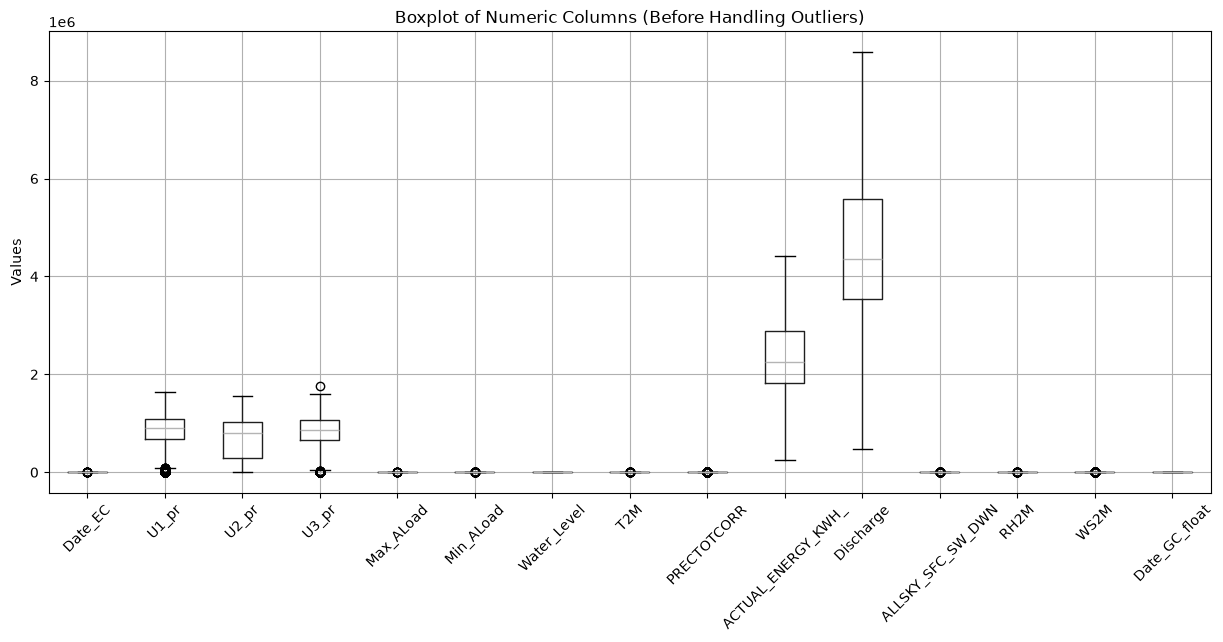

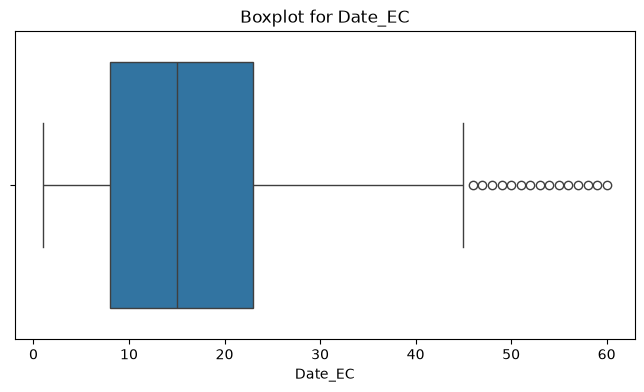

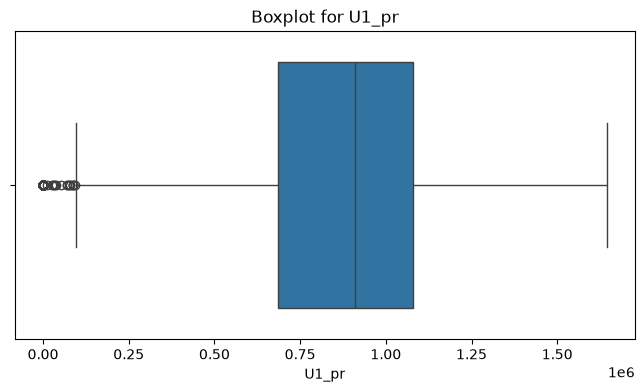

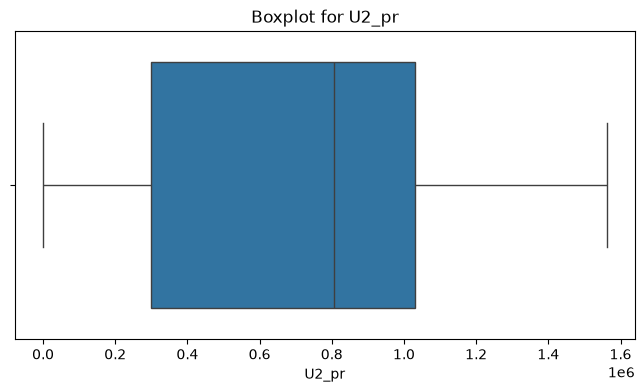

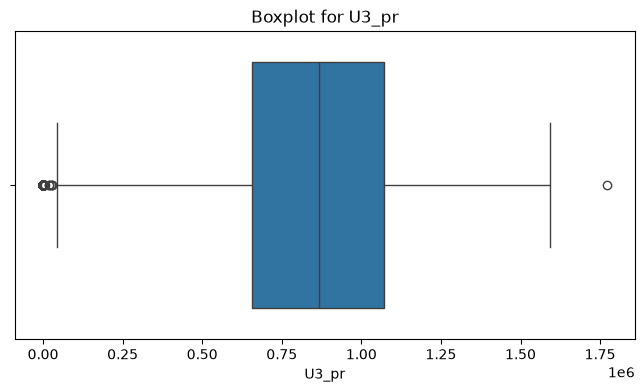

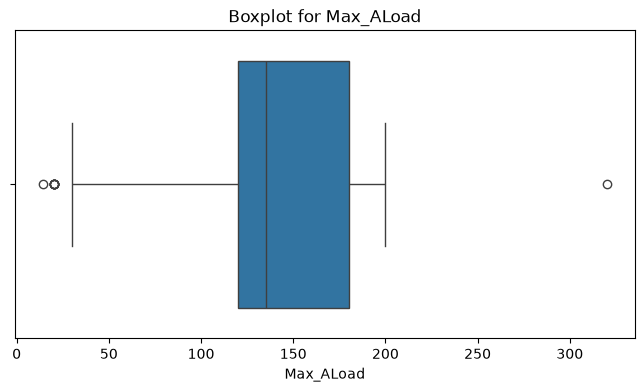

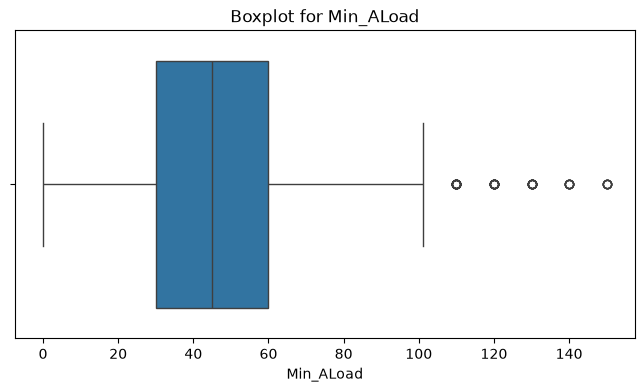

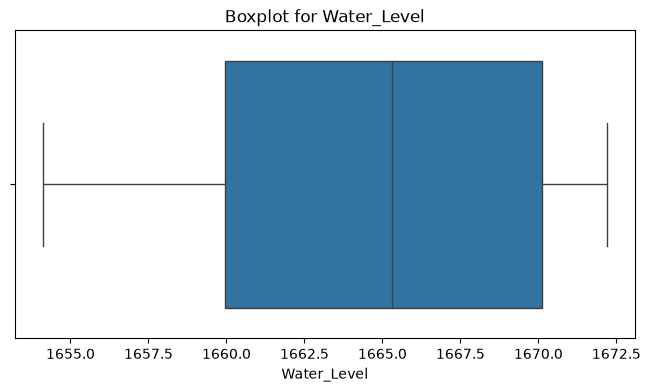

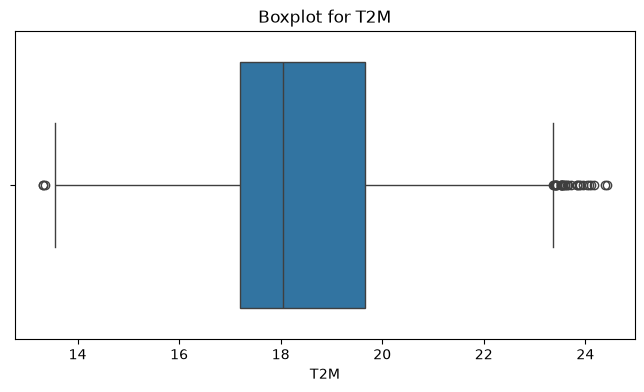

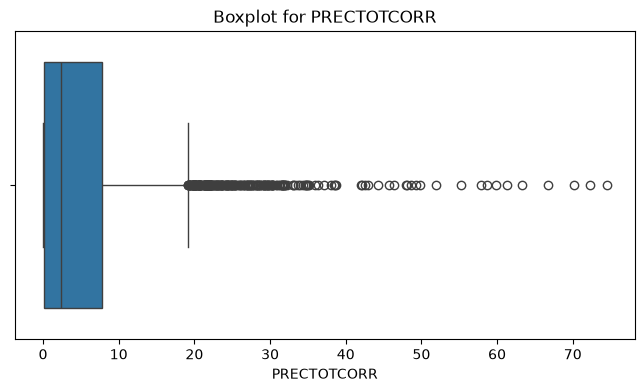

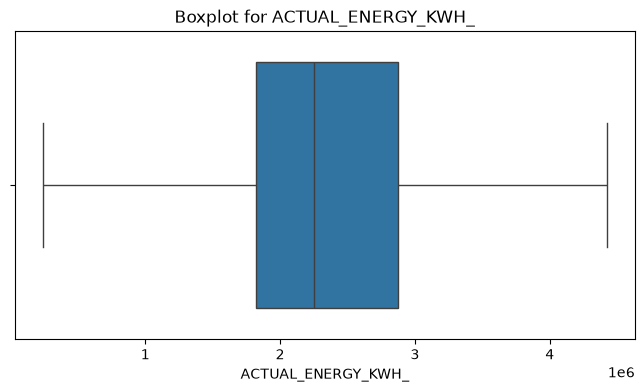

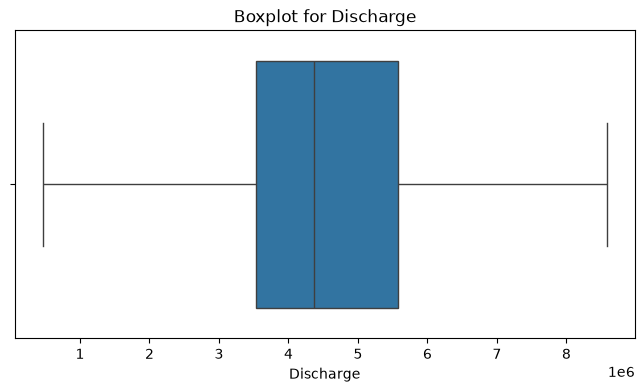

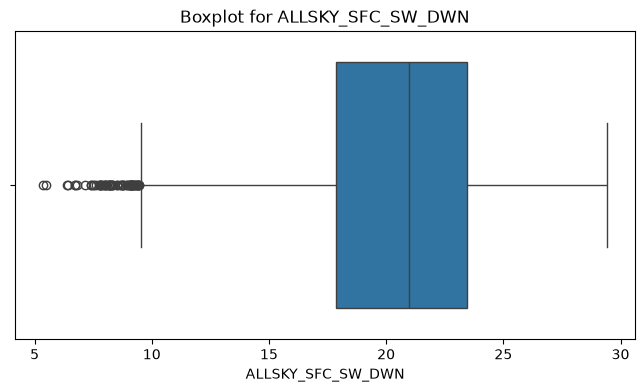

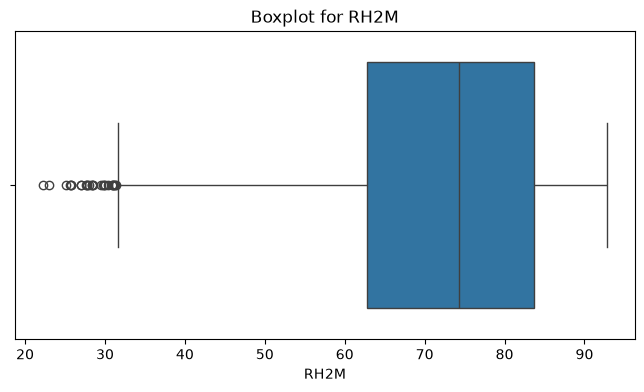

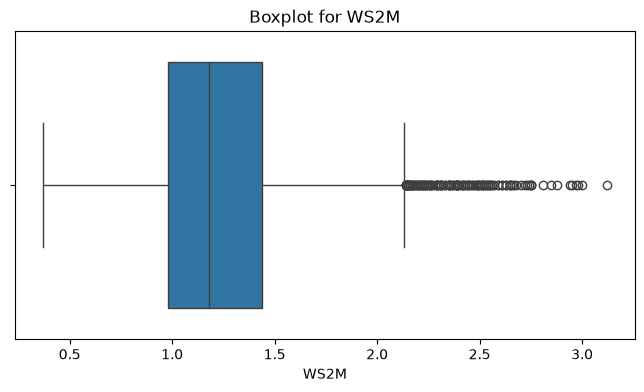

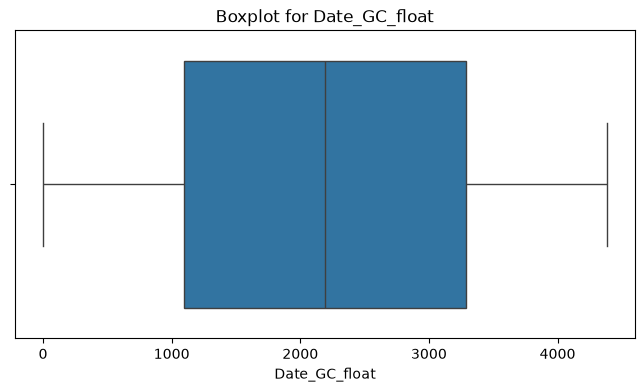

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Assuming 'df' is the DataFrame loaded for the selected power plant (e.g., from load_plant_data)
# Make a copy to avoid modifying original
df_numeric = df.select_dtypes(include=np.number).copy()

# Convert all numeric columns to ensure they are numeric (coerce errors to NaN)
for col in df_numeric.columns:
    df_numeric[col] = pd.to_numeric(df_numeric[col], errors='coerce')

# Select numeric columns only
numeric_cols = df_numeric.columns

# -----------------------------
# Outlier detection (IQR method)
# -----------------------------
outlier_info = []
for col in numeric_cols:
    Q1 = df_numeric[col].quantile(0.25)
    Q3 = df_numeric[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_count = df_numeric[(df_numeric[col] < lower) | (df_numeric[col] > upper)].shape[0]
   
    outlier_info.append({'Column': col, 'Outlier_Count': outlier_count})

# Display table of outliers
outlier_table = pd.DataFrame(outlier_info)
display(outlier_table)

# -----------------------------
# Boxplot for all numeric columns
# -----------------------------
plt.figure(figsize=(15, 6))
df_numeric[numeric_cols].boxplot(rot=45)
plt.title("Boxplot of Numeric Columns (Before Handling Outliers)")
plt.ylabel("Values")
plt.show()

# Optional: individual boxplots
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df_numeric[col])
    plt.title(f"Boxplot for {col}")
    plt.show()

In [31]:
import pandas as pd
import numpy as np

# Copy of original dataframe
df_minimized = df_numeric.copy()
numeric_cols = df_minimized.select_dtypes(include=np.number).columns

# Dictionary to store original and minimized outlier counts
outlier_counts = {}

# -----------------------------
# Minimize outliers via capping (Winsorization)
# -----------------------------
for col in numeric_cols:
    Q1 = df_minimized[col].quantile(0.25)
    Q3 = df_minimized[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    # Count original outliers
    original_outliers = df_minimized[(df_minimized[col] < lower) | (df_minimized[col] > upper)]
    
    # Apply capping
    df_minimized[col] = np.where(df_minimized[col] < lower, lower, df_minimized[col])
    df_minimized[col] = np.where(df_minimized[col] > upper, upper, df_minimized[col])
    
    # Count "outliers after minimization"
    minimized_outliers = df_minimized[(df_minimized[col] < lower) | (df_minimized[col] > upper)]
    
    # Store counts
    outlier_counts[col] = {"Original Outliers": len(original_outliers),
                           "After Minimization": len(minimized_outliers)}

# Display results in a table
outlier_df = pd.DataFrame(outlier_counts).T
display(outlier_df)


,Original Outliers,After Minimization
Date_EC,15,0
U1_pr,232,0
U2_pr,0,0
U3_pr,302,0
Max_ALoad,9,0
Min_ALoad,51,0
Water_Level,0,0
T2M,33,0
PRECTOTCORR,237,0
ACTUAL_ENERGY_KWH_,0,0


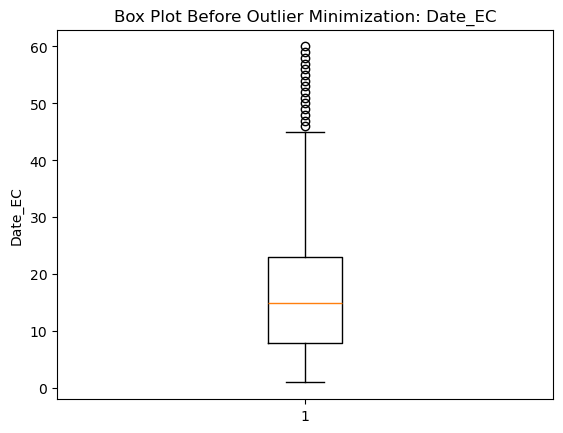

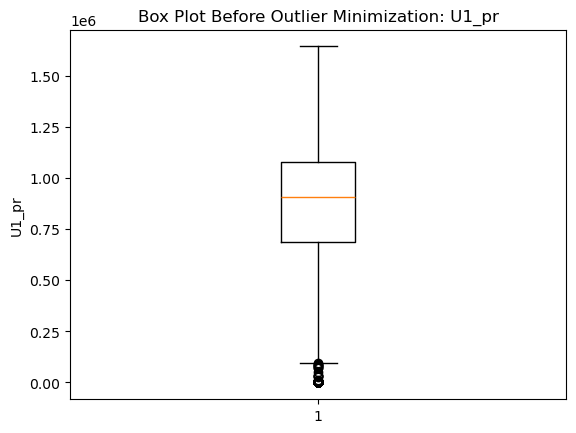

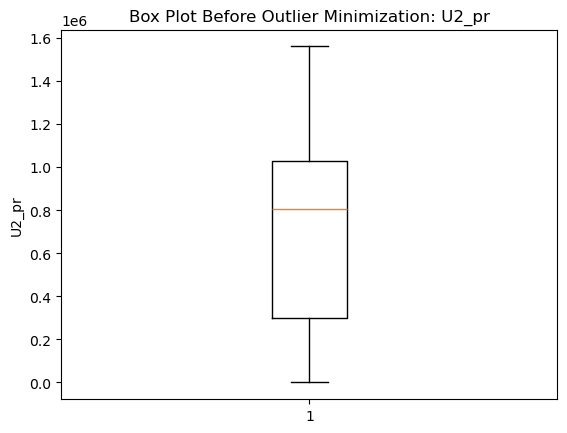

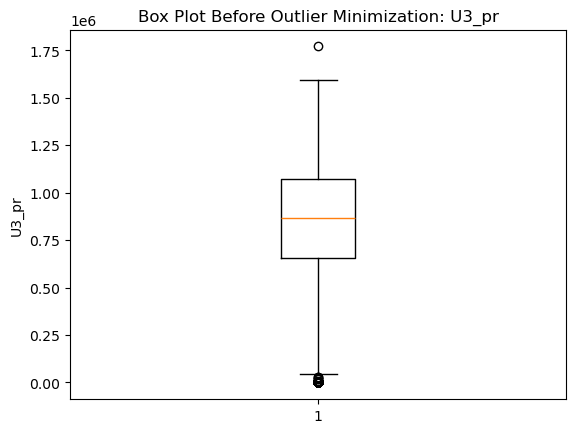

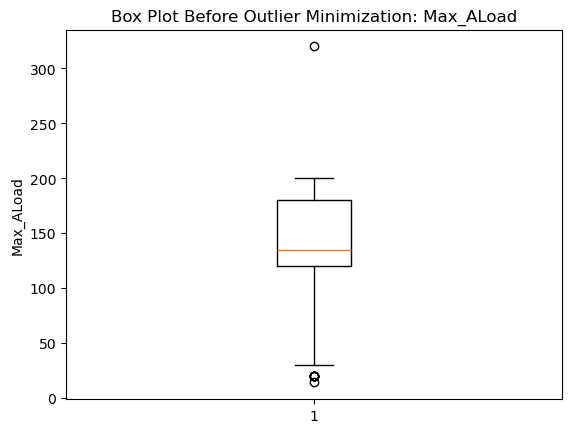

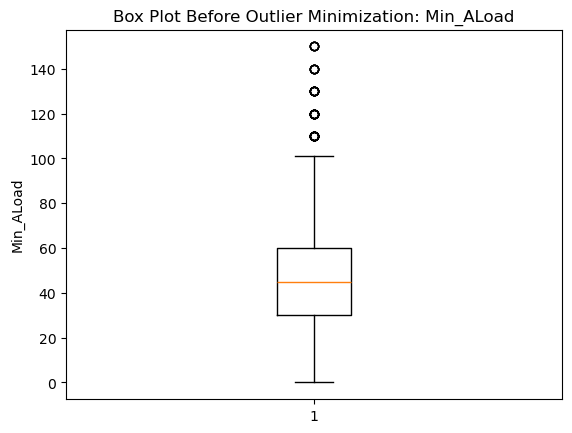

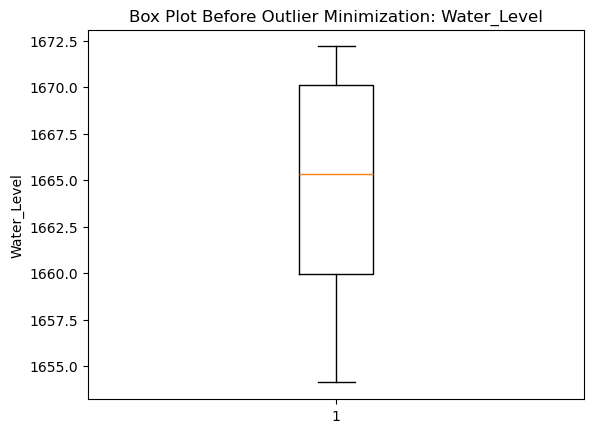

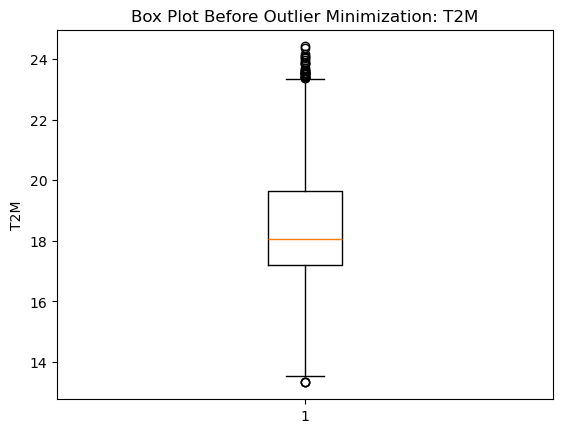

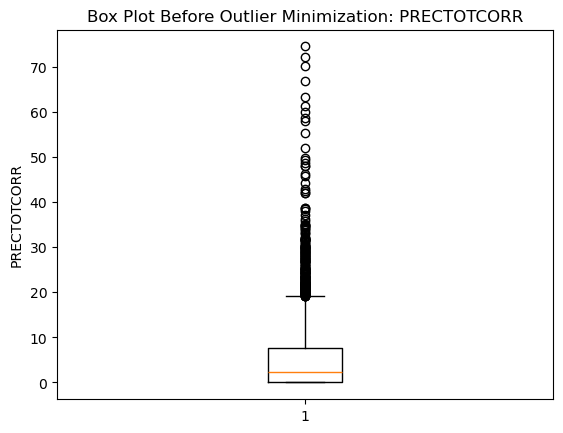

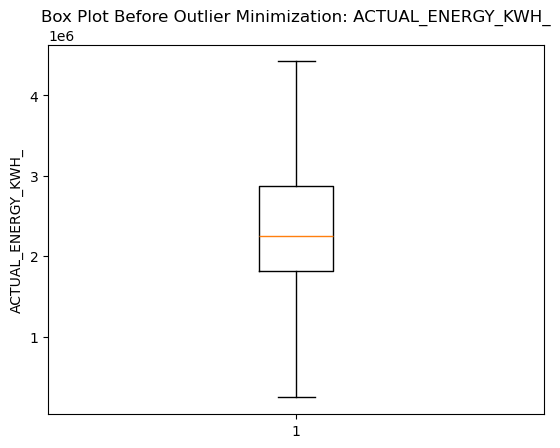

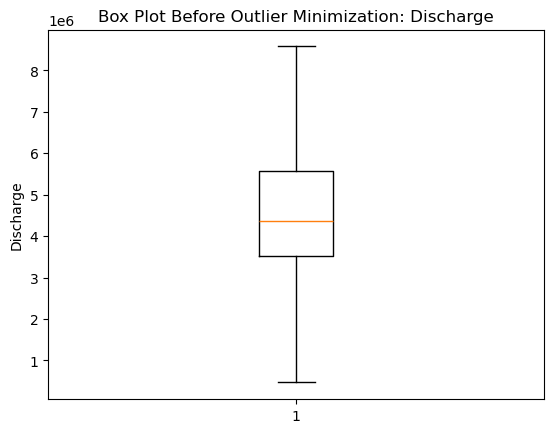

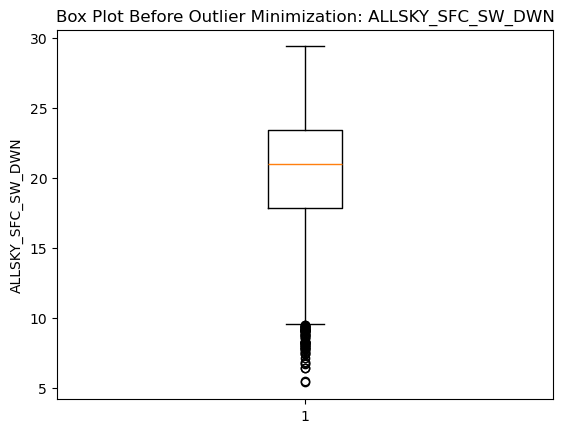

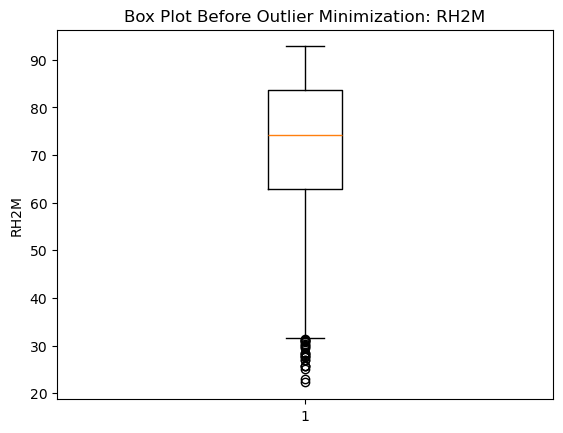

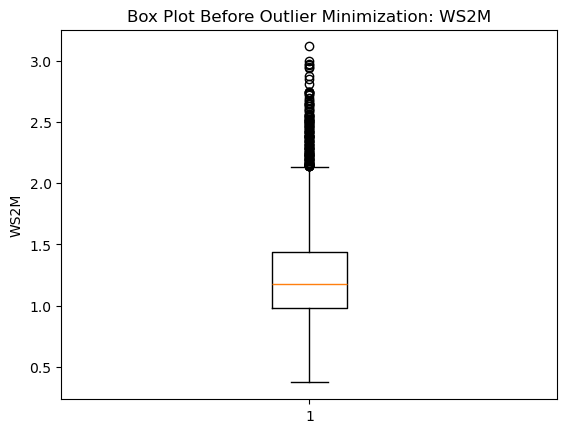

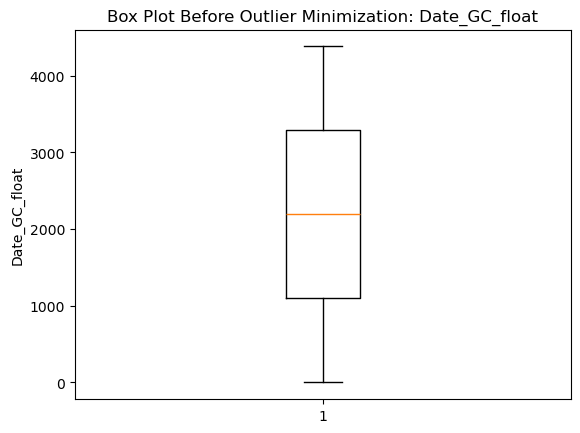

In [107]:
import matplotlib.pyplot as plt
import numpy as np

# Numeric columns BEFORE outlier handling
numeric_cols = df_numeric.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure()
    plt.boxplot(df_numeric[col].dropna())
    plt.title(f'Box Plot Before Outlier Minimization: {col}')
    plt.ylabel(col)
    plt.show()


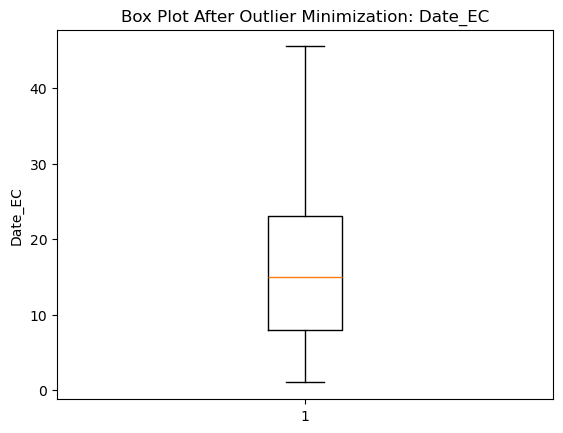

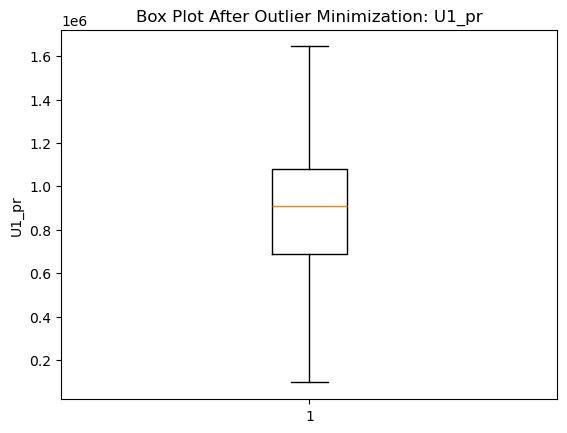

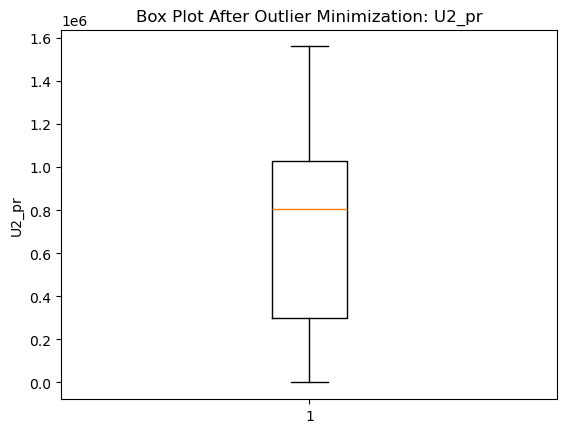

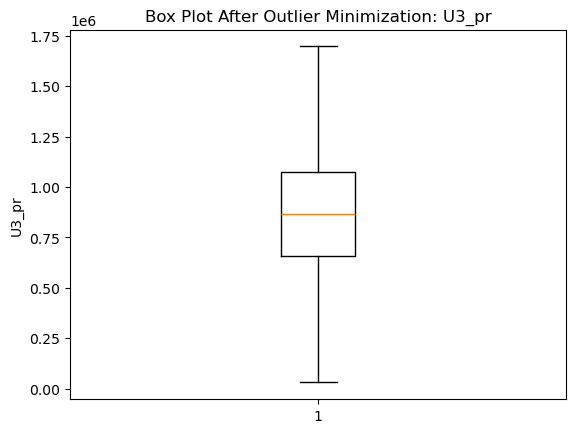

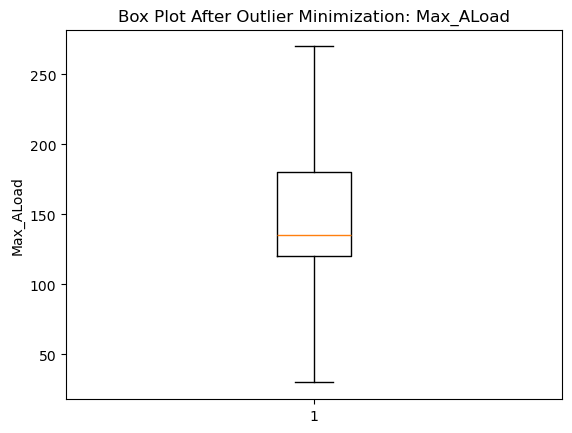

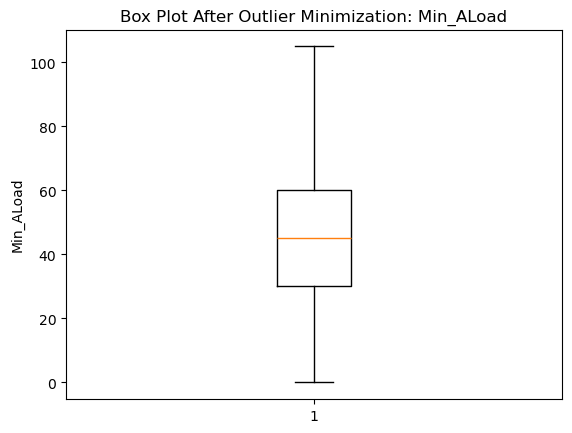

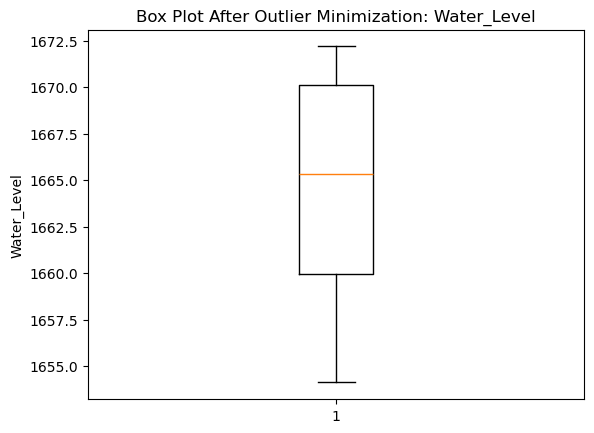

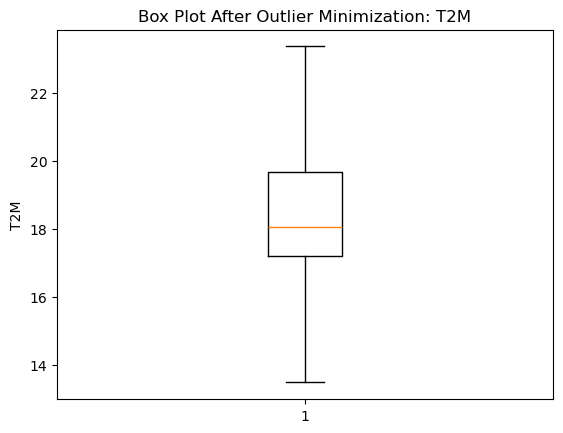

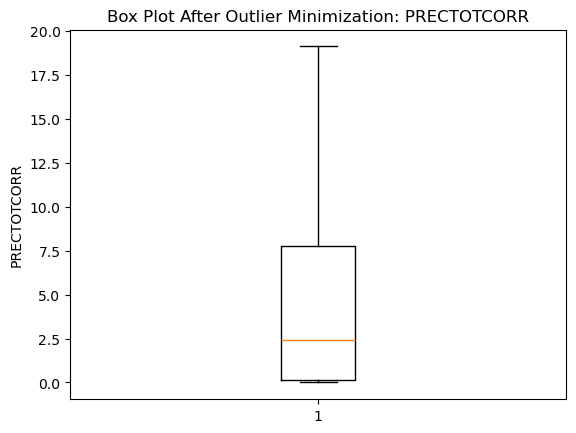

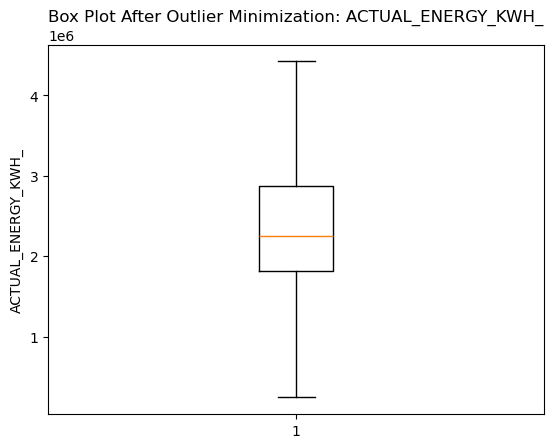

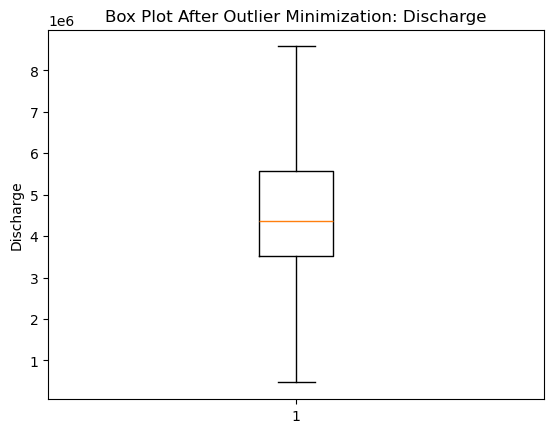

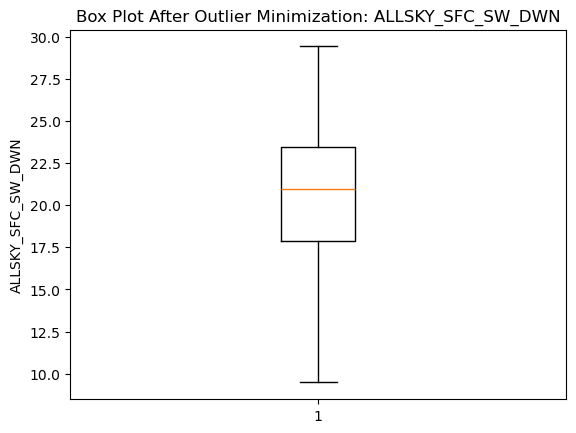

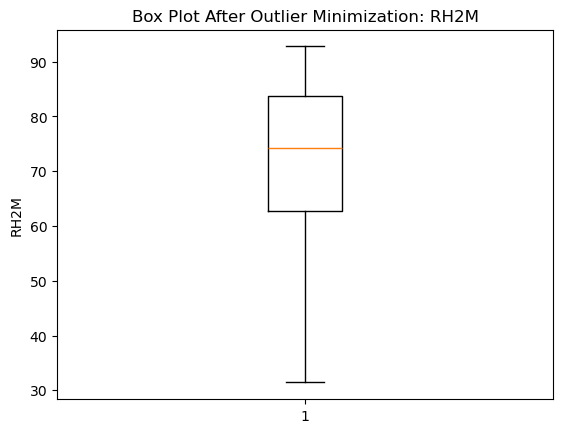

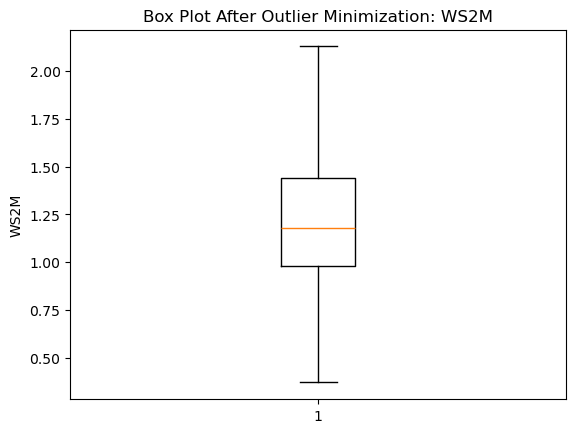

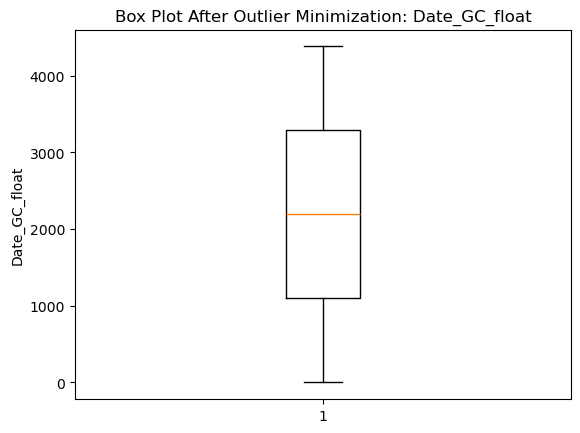

In [108]:
import matplotlib.pyplot as plt

# Use the minimized dataframe
numeric_cols = df_minimized.select_dtypes(include=np.number).columns

for col in numeric_cols:
    plt.figure()
    plt.boxplot(df_minimized[col].dropna())
    plt.title(f'Box Plot After Outlier Minimization: {col}')
    plt.ylabel(col)
    plt.show()


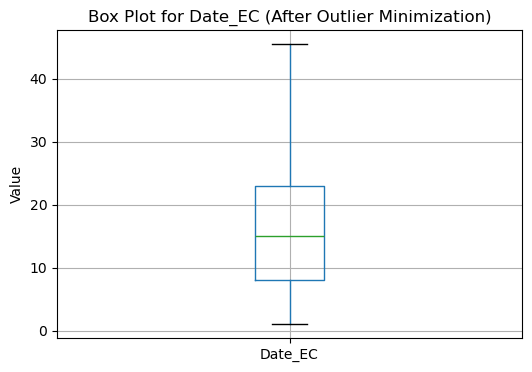

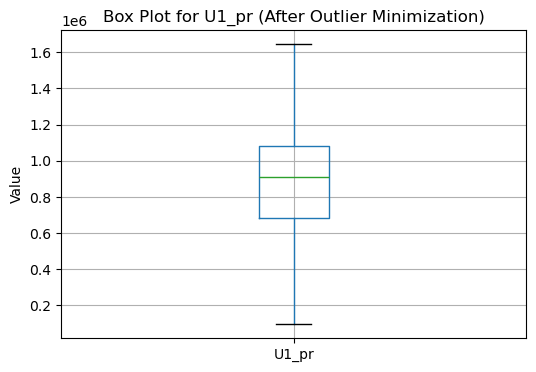

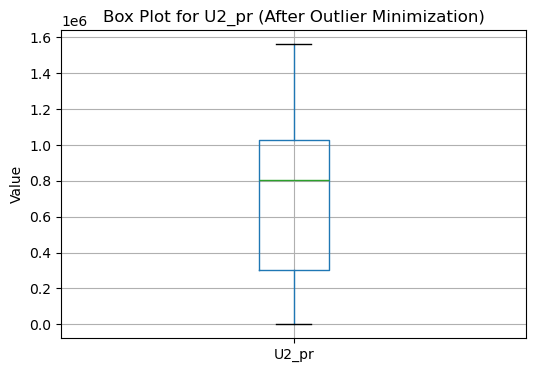

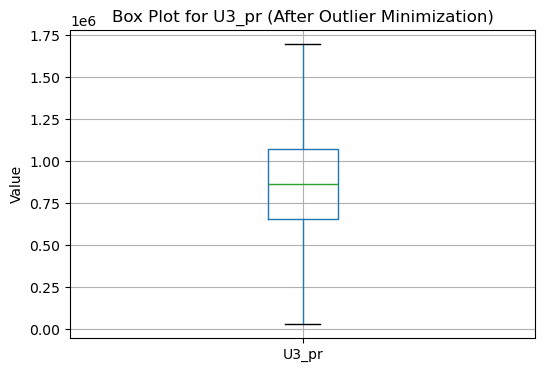

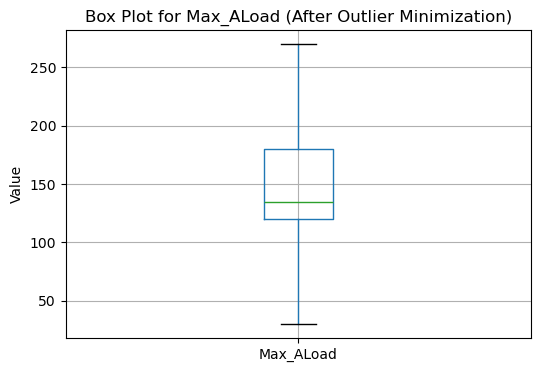

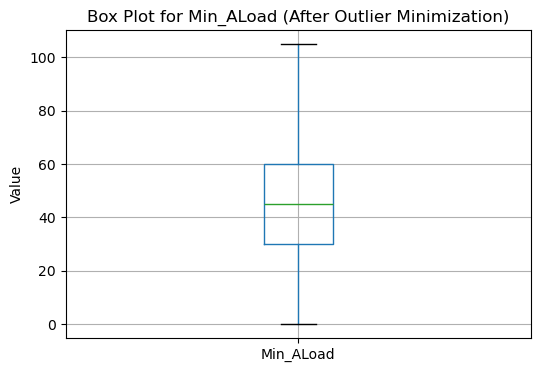

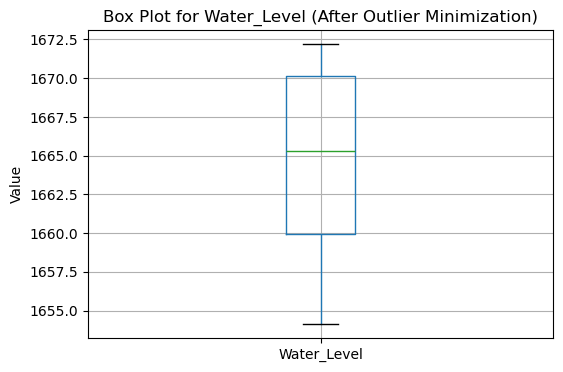

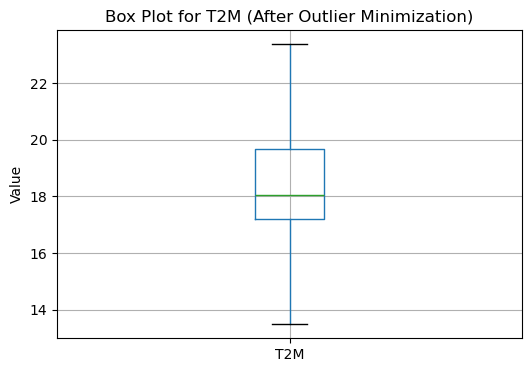

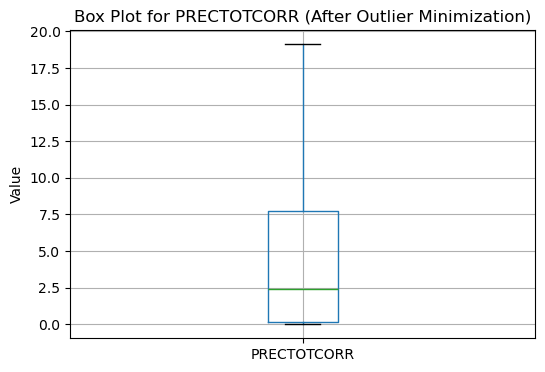

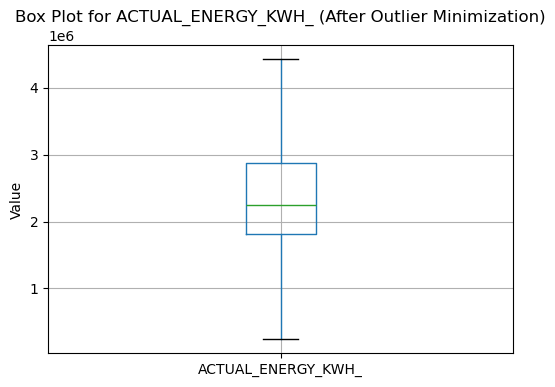

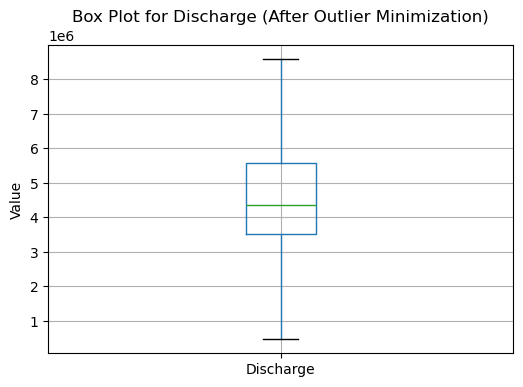

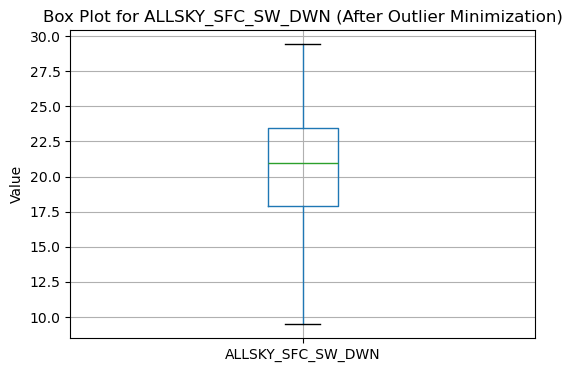

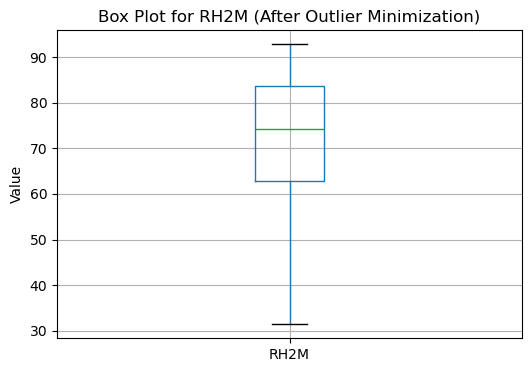

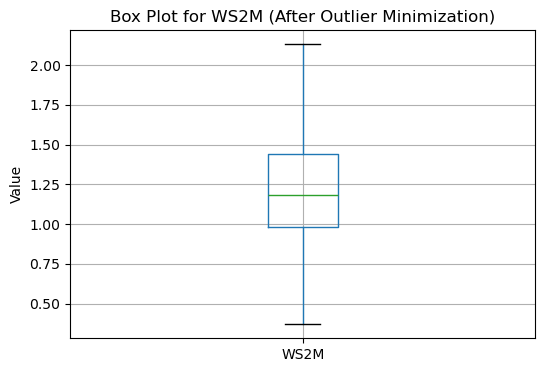

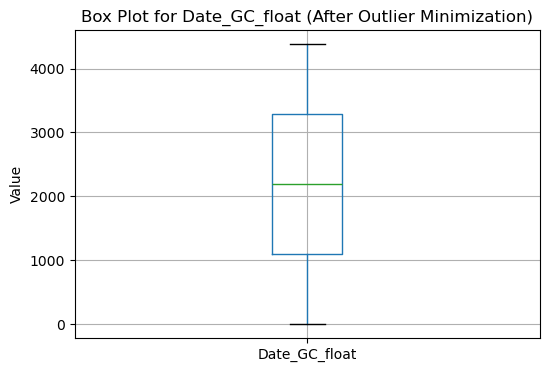

In [109]:
import matplotlib.pyplot as plt

# After the minimization code, add this to plot box plots for each variable separately
for col in numeric_cols:
    plt.figure(figsize=(6, 4))
    df_minimized.boxplot(column=col)
    plt.title(f'Box Plot for {col} (After Outlier Minimization)')
    plt.ylabel('Value')
    plt.show()



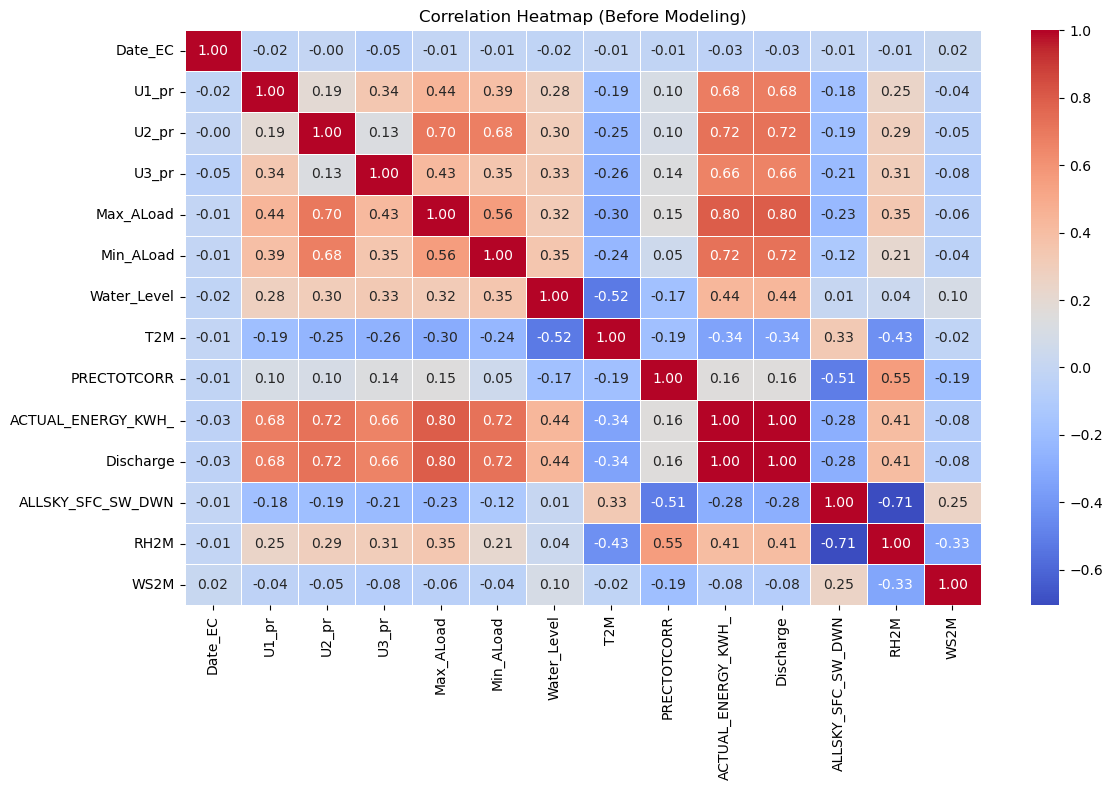

In [110]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numeric columns only
corr_df = df_numeric.select_dtypes(include='number').copy()

# Optional: drop index-like column if present
if 'Date_GC_float' in corr_df.columns:
    corr_df = corr_df.drop(columns=['Date_GC_float'])

# Compute correlation matrix
corr_matrix = corr_df.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap (Before Modeling)")
plt.tight_layout()
plt.show()


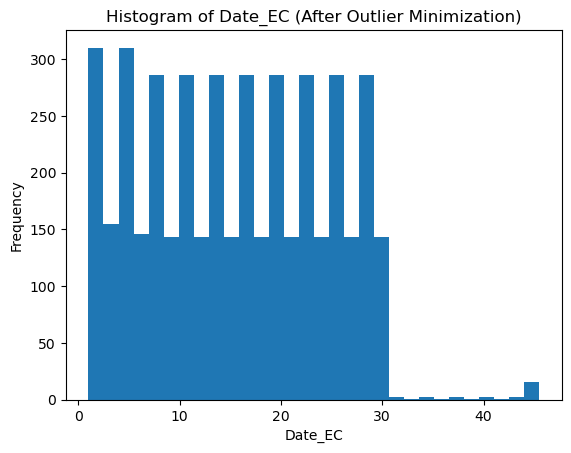

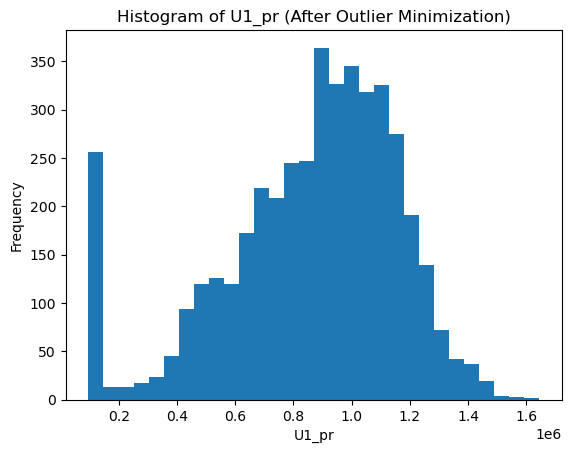

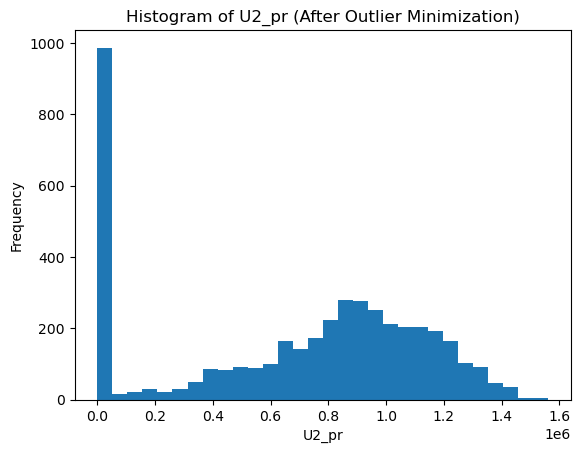

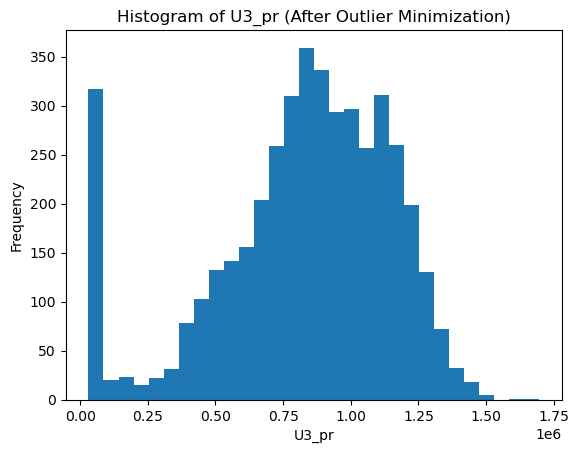

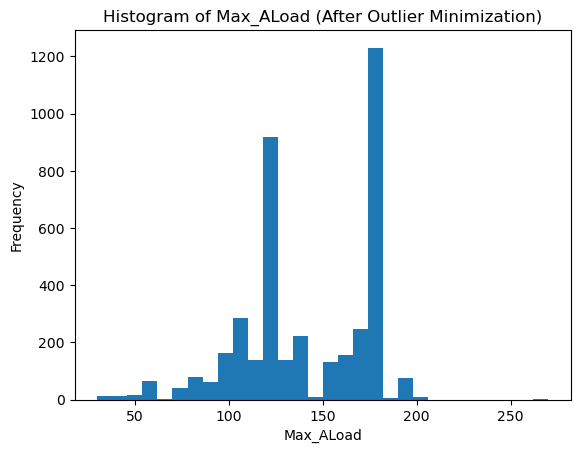

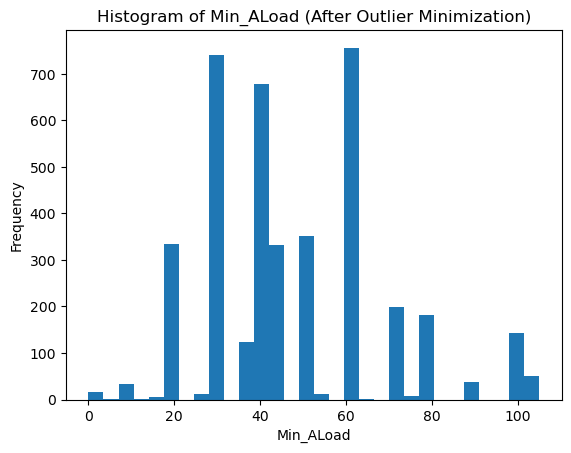

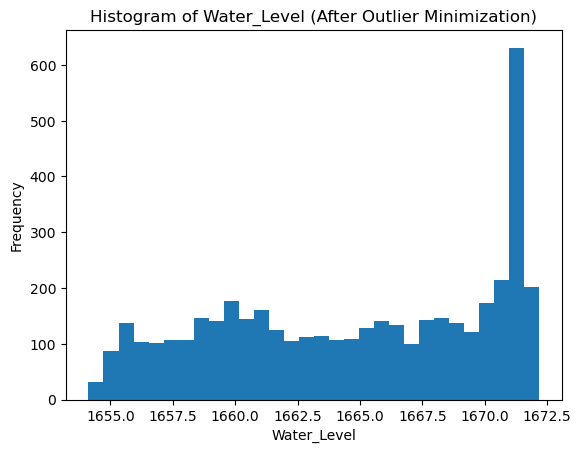

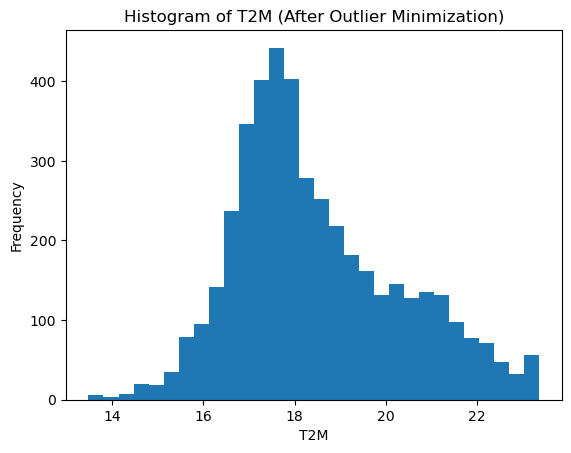

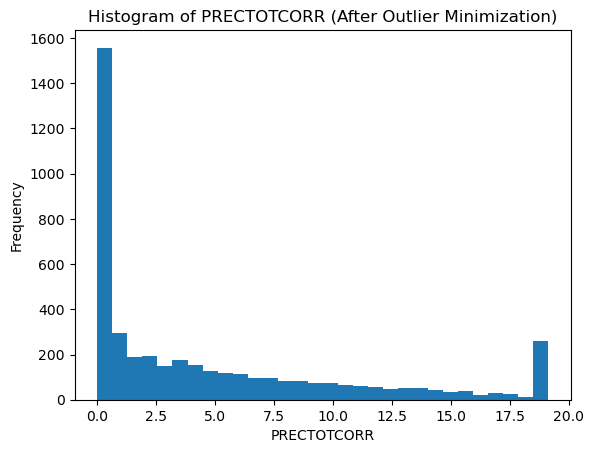

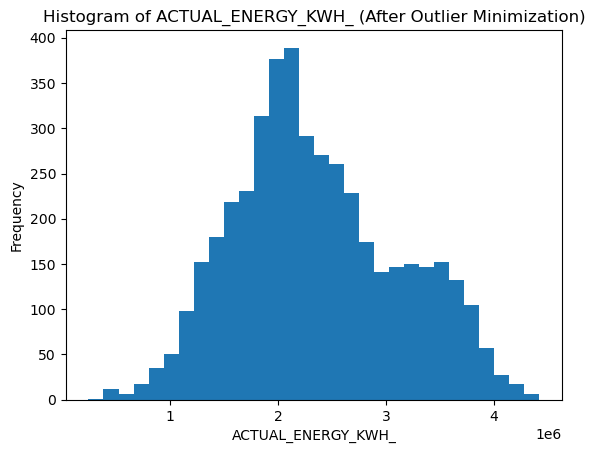

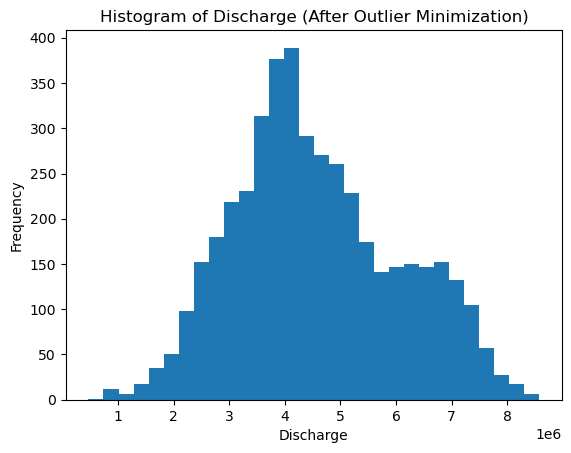

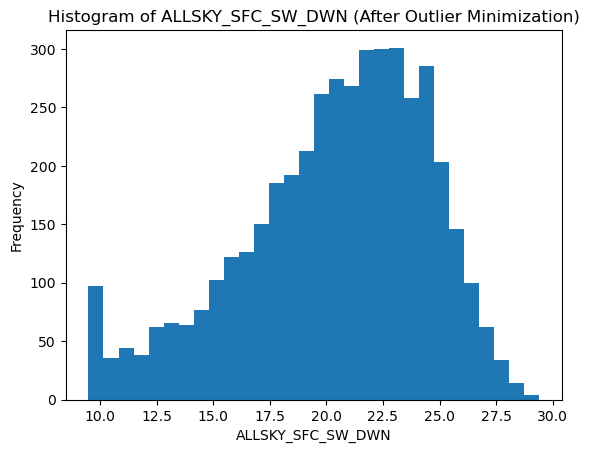

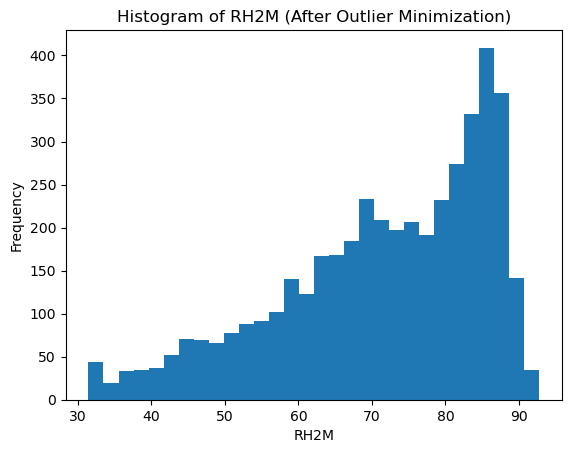

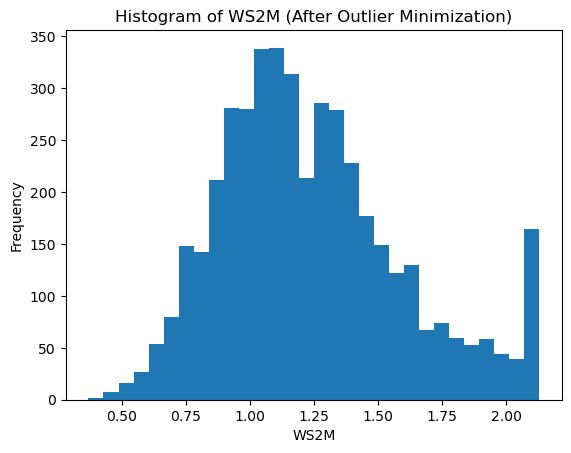

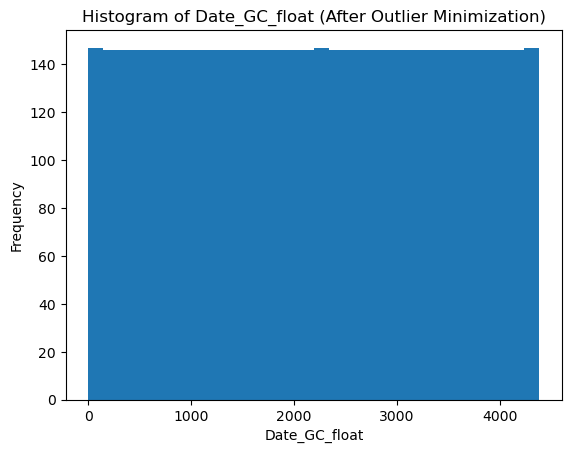

In [111]:
import matplotlib.pyplot as plt

# Use numeric columns only
num_cols = df_minimized.select_dtypes(include='number').columns

for col in num_cols:
    plt.figure()
    plt.hist(df_minimized[col].dropna(), bins=30)
    plt.title(f"Histogram of {col} (After Outlier Minimization)")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()


In [112]:
# Keywords to identify relevant features
KEYWORDS = ['level', 'U', 'energy', 'discharge', 'auxiliary',
            'load', 'u1', 'u2', 'u3', 'u4', 'u5', 'u6']

# Select columns whose names contain any keyword (case-insensitive)
selected_features = [
    col for col in df_numeric.columns
    if any(key in col.lower() for key in KEYWORDS)
]

# Create filtered DataFrame
df_selected = df_numeric[selected_features]

# Display results
print("✅ Selected Features:")
display(df_selected.head())

print("\n📌 Selected Feature Names:")
print(selected_features)


✅ Selected Features:


,U1_pr,U2_pr,U3_pr,Max_ALoad,Min_ALoad,Water_Level,ACTUAL_ENERGY_KWH_,Discharge
0,555000,564660.0,521620.0,120.0,35.0,1659.79,1641280.0,3184083.2
1,685860,684040.0,748340.0,120.0,40.0,1660.03,2118240.0,4109385.6
2,840800,953800.0,911660.0,150.0,50.0,1660.24,2706260.0,5250144.4
3,515760,556900.0,539720.0,120.0,30.0,1660.39,1612380.0,3128017.2
4,882940,880740.0,850960.0,120.0,80.0,1660.75,2614640.0,5072401.6



📌 Selected Feature Names:
['U1_pr', 'U2_pr', 'U3_pr', 'Max_ALoad', 'Min_ALoad', 'Water_Level', 'ACTUAL_ENERGY_KWH_', 'Discharge']


In [113]:
import pandas as pd

# Copy the numeric DataFrame
df_lagged = df_numeric.copy()

# Keywords to identify columns
KEYWORDS = ['level', 'U', 'energy', 'discharge', 'auxiliary',
            'load', 'u1', 'u2', 'u3', 'u4', 'u5', 'u6']

# Find columns that match any keyword (case-insensitive)
selected_cols = [col for col in df_lagged.columns 
                 if any(k.lower() in col.lower() for k in KEYWORDS)]

# Create lag-1 features for these columns
for col in selected_cols:
    df_lagged[f'{col}_lag1'] = df_lagged[col].shift(1)

# Fill first row NaN from lag with 0
df_lagged.fillna(0, inplace=True)

# Display first few rows to verify
display(df_lagged.head())


,Date_EC,U1_pr,U2_pr,U3_pr,Max_ALoad,Min_ALoad,Water_Level,T2M,PRECTOTCORR,ACTUAL_ENERGY_KWH_,...,WS2M,Date_GC_float,U1_pr_lag1,U2_pr_lag1,U3_pr_lag1,Max_ALoad_lag1,Min_ALoad_lag1,Water_Level_lag1,ACTUAL_ENERGY_KWH__lag1,Discharge_lag1
0,1,555000,564660.0,521620.0,120.0,35.0,1659.79,15.93,21.76,1641280.0,...,1.63,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0
1,2,685860,684040.0,748340.0,120.0,40.0,1660.03,15.75,5.64,2118240.0,...,1.55,1.0,555000.0,564660.0,521620.0,120.0,35.0,1659.79,1641280.0,3184083.2
2,3,840800,953800.0,911660.0,150.0,50.0,1660.24,16.44,15.16,2706260.0,...,1.22,2.0,685860.0,684040.0,748340.0,120.0,40.0,1660.03,2118240.0,4109385.6
3,4,515760,556900.0,539720.0,120.0,30.0,1660.39,15.62,16.53,1612380.0,...,1.44,3.0,840800.0,953800.0,911660.0,150.0,50.0,1660.24,2706260.0,5250144.4
4,5,882940,880740.0,850960.0,120.0,80.0,1660.75,15.95,8.24,2614640.0,...,1.36,4.0,515760.0,556900.0,539720.0,120.0,30.0,1660.39,1612380.0,3128017.2


In [114]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
import xgboost as xgb

# --- Copy numeric dataframe ---
df_model = df_numeric.copy()

# --- Desired target columns (not all plants have all of them) ---
target_columns = [
    'U1_pr', 'U2_pr', 'U3_pr', 'U4_pr',
    'Max_ALoad', 'Min_ALoad', 'Auxiliary',
    'Actual_Energy', 'Discharge_water'
]

# ✅ Keep only targets that actually exist
available_targets = [c for c in target_columns if c in df_model.columns]

if len(available_targets) == 0:
    raise ValueError("❌ No target columns found in df_model!")

print("✅ Using target columns:", available_targets)

# --- Features and targets ---
X = df_model.drop(columns=available_targets)
y = df_model[available_targets]

# --- Ensure numeric ---
X = X.apply(pd.to_numeric, errors='coerce')
y = y.apply(pd.to_numeric, errors='coerce')

# --- Drop rows with missing values ---
data = pd.concat([X, y], axis=1).dropna()
X = data[X.columns]
y = data[y.columns]

# --- Train-test split (80/20) ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("✅ Train-test split complete:")
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

# --- Define models ---
models = {
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Linear Regression": LinearRegression(),
    "SVR": SVR(),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "XGBoost": xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42),
    "KNN": KNeighborsRegressor(n_neighbors=5)
}

# --- Train & evaluate ---
results = {}

for name, model in models.items():
    multi_model = MultiOutputRegressor(model)
    multi_model.fit(X_train, y_train)
    y_pred = multi_model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred, multioutput='uniform_average')

    results[name] = {"MSE": mse, "R2": r2}

# --- Display results ---
results_df = pd.DataFrame(results).T.sort_values(by="R2", ascending=False)
display(results_df)


✅ Using target columns: ['U1_pr', 'U2_pr', 'U3_pr', 'Max_ALoad', 'Min_ALoad']
✅ Train-test split complete:
X_train: (3214, 10), X_test: (804, 10)
y_train: (3214, 5), y_test: (804, 5)


,MSE,R2
Random Forest,1.102698e+10,0.844094
XGBoost,1.260742e+10,0.826604
Gradient Boosting,1.503219e+10,0.808139
Decision Tree,2.066510e+10,0.691932
Linear Regression,4.231402e+10,0.545342
KNN,4.706026e+10,0.509343
SVR,9.060349e+10,0.221907


In [115]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor

# ---------------------------------------------------
# 1️⃣ SELECT TARGET COLUMNS USING KEYWORDS
# ---------------------------------------------------

KEYWORDS = [
    'level', 'U', 'energy', 'discharge', 'auxiliary',
    'load', 'u1', 'u2', 'u3', 'u4', 'u5', 'u6'
]

df_ts = df_numeric.copy()
df_ts = df_ts.sort_index().reset_index(drop=True)

targets = [
    col for col in df_ts.columns
    if any(k.lower() in col.lower() for k in KEYWORDS)
]

if len(targets) == 0:
    raise ValueError("❌ No target columns matched the given keywords.")

print("✅ Selected target columns:", targets)

# ---------------------------------------------------
# 2️⃣ CREATE LAG FEATURES
# ---------------------------------------------------

LAGS = [1, 2, 3, 7, 14]

df_lag = df_ts.copy()

for col in targets:
    for lag in LAGS:
        df_lag[f"{col}_lag{lag}"] = df_lag[col].shift(lag)

df_lag = df_lag.dropna().reset_index(drop=True)

X = df_lag[[c for c in df_lag.columns if '_lag' in c]].values
y = df_lag[targets].values

# ---------------------------------------------------
# 3️⃣ TRAIN FAST MODEL (No MultiOutputRegressor)
# ---------------------------------------------------

model = RandomForestRegressor(
    n_estimators=80,   # reduced trees for speed
    max_depth=10,      # shallower trees = faster
    random_state=42,
    n_jobs=-1
)

model.fit(X, y)
print("✅ Model trained successfully")

# ---------------------------------------------------
# 4️⃣ ULTRA-FAST RECURSIVE FORECAST (365 DAYS)
# ---------------------------------------------------

n_forecast = 365
history_values = df_ts[targets].values.copy()
predictions = []

n_targets = len(targets)

for _ in range(n_forecast):

    X_step = []

    for col_idx in range(n_targets):
        for lag in LAGS:
            X_step.append(history_values[-lag, col_idx])

    X_step = np.array(X_step).reshape(1, -1)

    y_pred = model.predict(X_step)[0]
    predictions.append(y_pred)

    history_values = np.vstack([history_values, y_pred])

# ---------------------------------------------------
# 5️⃣ BUILD FINAL FORECAST DATAFRAME
# ---------------------------------------------------

forecast_2025 = pd.DataFrame(predictions, columns=targets)
forecast_2025["Date"] = pd.date_range(
    start="2025-01-01",
    periods=365,
    freq="D"
)

forecast_2025.set_index("Date", inplace=True)

display(forecast_2025.head())
display(forecast_2025.tail())


✅ Selected target columns: ['U1_pr', 'U2_pr', 'U3_pr', 'Max_ALoad', 'Min_ALoad', 'Water_Level', 'ACTUAL_ENERGY_KWH_', 'Discharge']
✅ Model trained successfully


,U1_pr,U2_pr,U3_pr,Max_ALoad,Min_ALoad,Water_Level,ACTUAL_ENERGY_KWH_,Discharge
Date,,,,,,,,
2025-01-01,1.075941e+06,1.147398e+06,1.164159e+06,181.264169,74.052687,1668.796583,3.387498e+06,6.571746e+06
2025-01-02,1.064831e+06,1.111114e+06,1.096088e+06,178.188503,62.553775,1666.633571,3.272034e+06,6.347745e+06
2025-01-03,1.002050e+06,1.043809e+06,1.019200e+06,176.749522,59.039364,1666.360693,3.065060e+06,5.946216e+06
2025-01-04,1.029674e+06,1.054487e+06,1.022329e+06,176.306505,58.450649,1665.522430,3.106490e+06,6.026592e+06
2025-01-05,9.758056e+05,1.063287e+06,1.004265e+06,179.282598,56.962356,1665.198719,3.043358e+06,5.904114e+06


,U1_pr,U2_pr,U3_pr,Max_ALoad,Min_ALoad,Water_Level,ACTUAL_ENERGY_KWH_,Discharge
Date,,,,,,,,
2025-12-27,1.043581e+06,1.079516e+06,1.046118e+06,178.469222,57.540890,1665.839006,3.169214e+06,6.148276e+06
2025-12-28,1.043818e+06,1.080295e+06,1.046763e+06,178.432825,57.604174,1665.875673,3.170875e+06,6.151497e+06
2025-12-29,1.042766e+06,1.079248e+06,1.045344e+06,178.469445,57.510665,1665.843828,3.167358e+06,6.144675e+06
2025-12-30,1.042363e+06,1.080934e+06,1.044927e+06,178.471668,57.399669,1665.819958,3.168224e+06,6.146355e+06
2025-12-31,1.042766e+06,1.079248e+06,1.045344e+06,178.469445,57.510665,1665.843828,3.167358e+06,6.144675e+06


In [ ]:
# ================= DAILY 365-DAY FORECAST (2025) =================

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor

# --- Copy lagged dataframe ---
df_forecast = df_lagged.copy()

# --- Target keywords ---
KEYWORDS = ['level','u','energy','discharge','auxiliary','load']

# --- Identify target columns (original, NOT lagged) ---
target_cols = [
    col for col in df_forecast.columns
    if any(k in col.lower() for k in KEYWORDS)
    and not col.endswith('_lag1')
]

# --- Feature columns (everything else) ---
feature_cols = [col for col in df_forecast.columns if col not in target_cols]

print("🎯 Targets:", target_cols)
print("📊 Features:", len(feature_cols))

# --- Train data ---
X = df_forecast[feature_cols]
y = df_forecast[target_cols]

# --- Train model ---
model = MultiOutputRegressor(
    RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        random_state=42,
        n_jobs=-1
    )
)

model.fit(X, y)

# --- Start forecasting from last known day ---
last_row = df_forecast.iloc[-1].copy()
future_predictions = []

n_days = 365

for day in range(n_days):
    X_input = last_row[feature_cols].values.reshape(1, -1)
    
    # Predict next day
    y_pred = model.predict(X_input)[0]
    future_predictions.append(y_pred)

    # Update lag features dynamically
    for i, col in enumerate(target_cols):
        last_row[f'{col}_lag1'] = y_pred[i]
        last_row[col] = y_pred[i]

# --- Create forecast DataFrame ---
future_dates = pd.date_range(start='2025-01-01', periods=n_days, freq='D')

forecast_df = pd.DataFrame(
    future_predictions,
    columns=[f'{c}_forecast' for c in target_cols],
    index=future_dates
)

print("\n✅ Forecast completed for 365 days (2025)")
display(forecast_df.head(10))
# ================================================================


🎯 Targets: ['U1_pr', 'U2_pr', 'U3_pr', 'Max_ALoad', 'Min_ALoad', 'Water_Level', 'ACTUAL_ENERGY_KWH_', 'Discharge']
📊 Features: 15


In [121]:
# Cell 2: Functions, App Definition, Layouts, Callbacks, and Run

# --- Data Processing Functions ---
def preprocess_data(df, date_col):
    if df.empty or date_col not in df.columns:
        return df
    df[date_col] = pd.to_datetime(df[date_col], errors='coerce')
    df = df.dropna(subset=[date_col]).sort_values(date_col)
    for col in df.columns:
        if col != date_col:
            if pd.api.types.is_numeric_dtype(df[col]):
                df[col] = df[col].fillna(df[col].median())
            else:
                df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else 'Unknown')
    return df.reset_index(drop=True)

# =================================================================================
# === CORRECTED FUNCTION: Loads and filters the actual data from the source file ===
# =================================================================================
def load_default_data(power_plant):
    if power_plant not in POWER_PLANT_DATA:
        return pd.DataFrame(), None, f"Power plant {power_plant} not found."
   
    config = POWER_PLANT_DATA[power_plant]
    file_path, date_col = config['path'], config['date_col']
    if not os.path.exists(file_path):
        return pd.DataFrame(), None, f"File not found for {power_plant} at {file_path}."
       
    try:
        # If data is already processed and cached, return it.
        if power_plant in data_cache['default']['preprocessed_dfs']:
            return data_cache['default']['preprocessed_dfs'][power_plant], date_col, None
        # 1. Load the entire CSV file.
        df_full = pd.read_csv(file_path)
       
        # 2. Correctly filter for the selected power plant. This ensures all rows are included.
        df_filtered = df_full[df_full['Power_Plant_Name'] == power_plant].copy() if 'Power_Plant_Name' in df_full.columns else df_full.copy()
       
        # 3. Preprocess the correctly filtered and complete dataset.
        df_preprocessed = preprocess_data(df_filtered, date_col)
       
        if df_preprocessed.empty:
            return pd.DataFrame(), None, f"No valid data after preprocessing for {power_plant}."
        # 4. Cache the complete, processed data.
        data_cache['default']['preprocessed_dfs'][power_plant] = df_preprocessed
        data_cache['default']['date_col'] = date_col
       
        return df_preprocessed, date_col, None
       
    except Exception as e:
        return pd.DataFrame(), None, f"Error loading data for {power_plant}: {e}"

def load_plant_data(power_plant, source='default'):
    """Load data for a specific power plant from the specified source"""
    if source == 'default':
        return load_default_data(power_plant)
    else:
        # Handle uploaded data if needed
        if power_plant in data_cache['uploaded']['preprocessed_dfs']:
            return data_cache['uploaded']['preprocessed_dfs'][power_plant], data_cache['uploaded']['date_col'], None
        return pd.DataFrame(), None, "No uploaded data available"

def get_available_columns(df, date_col, power_plant, source='default'):
    if df.empty or date_col is None:
        return [], [], None, None
   
    # Get feature columns
    if source == 'default' and power_plant in POWER_PLANT_DATA:
        feature_cols = [col for col in POWER_PLANT_DATA[power_plant]['feature_cols'] if col in df.columns and pd.api.types.is_numeric_dtype(df[col])]
    else:
        feature_cols = [col for col in df.columns if any(p.lower() in col.lower() for p in FEATURE_COL_PREFIXES) and pd.api.types.is_numeric_dtype(df[col])]
   
    # Get potential target columns
    potential_targets = [col for col in df.columns if col not in [date_col] + feature_cols + EXCLUDE_COLS and 'date ec' not in col.lower() and any(k in col.lower() for k in ALLOWED_TARGET_KEYWORDS)]
   
    # Separate numeric and categorical targets
    numeric_targets = [col for col in potential_targets if pd.api.types.is_numeric_dtype(df[col])]
    categorical_targets = [col for col in potential_targets if not pd.api.types.is_numeric_dtype(df[col])]
   
    # Combine all target options
    target_options = numeric_targets + categorical_targets
   
    # Select default target column
    if source == 'default' and power_plant in POWER_PLANT_DATA:
        target_cols = [col for col in POWER_PLANT_DATA[power_plant]['target_vars'] if col in target_options]
        target_col = target_cols[0] if target_cols else (numeric_targets[0] if numeric_targets else (categorical_targets[0] if categorical_targets else None))
    else:
        target_col = numeric_targets[0] if numeric_targets else (categorical_targets[0] if categorical_targets else None)
   
    task_type = 'regression' if target_col in numeric_targets else ('classification' if target_col in categorical_targets else None)
   
    return feature_cols, target_options, target_col, task_type

def create_features(df_input, date_col):
    df = df_input.copy()
    df['year'] = df[date_col].dt.year
    df['month'] = df[date_col].dt.month
    df['day'] = df[date_col].dt.day
    df['dayofyear'] = df[date_col].dt.dayofyear
    df['weekday'] = df[date_col].dt.weekday
    return df

# === Initialize Dash App ===
app = JupyterDash(__name__, external_stylesheets=[dbc.themes.BOOTSTRAP, 'https://cdnjs.cloudflare.com/ajax/libs/font-awesome/5.15.4/css/all.min.css'])
app.title = "Ethiopian Power Plant Forecast Dashboard"

# === App Layout ===
app.layout = html.Div([
    dcc.Store(id='intermediate-data-store'),
    # Notification modal
    dbc.Modal([
        dbc.ModalHeader("High Deviation Forecast Alerts"),
        dbc.ModalBody(id='notification-body'),
        dbc.ModalFooter(dbc.Button("Close", id="close-notification-modal", className="ml-auto")),
    ], id="notification-modal", is_open=False, size="xl"),
   
    html.Div([
        html.H2("📊 Ethiopian Electric Power Plant Forecast", style={'textAlign': 'left', 'fontWeight': 'bold', 'display': 'inline-block'}),
        html.Div([
            dbc.Button(id='notification-icon', n_clicks=0, color="secondary", className="position-relative", style={'fontSize': '1.2rem', 'padding': '5px 10px'}),
        ], style={'display': 'inline-block', 'verticalAlign': 'top', 'paddingTop': '5px', 'marginLeft': 'auto'})
    ], style={'display': 'flex', 'alignItems': 'center', 'padding': '20px'}),
   
    html.Div([
        html.Div([html.Label("Select Power Plant:", style={'fontWeight': 'bold'}), dcc.Dropdown(id='power-plant-selector', options=[{'label': p, 'value': p} for p in POWER_PLANT_DATA.keys()], value='Gibe 1', clearable=False)], style={'width': '33%', 'display': 'inline-block', 'marginRight': '1%'}),
        html.Div([html.Label("Select Target Variable:", style={'fontWeight': 'bold'}), dcc.Dropdown(id='target-selector', placeholder="Select a target variable")], style={'width': '33%', 'display': 'inline-block', 'marginRight': '1%'}),
        html.Div([html.Label("Forecast Period:", style={'fontWeight': 'bold'}), dcc.Dropdown(id='horizon-period-selector', options=[{'label': 'Daily', 'value': 'daily'}, {'label': 'Weekly', 'value': 'weekly'}, {'label': 'Monthly', 'value': 'monthly'}, {'label': 'Yearly', 'value': 'yearly'}], value='monthly', clearable=False), html.Div(id='daily-options', children=[dcc.Dropdown(id='day-of-month-selector', placeholder='Select Day(s) of Month', options=[{'label': str(d), 'value': d} for d in range(1, 32)], multi=True)], style={'display': 'none', 'marginTop': '5px'}), html.Div(id='month-year-options', children=[dcc.Dropdown(id='month-selector', placeholder='Select Months', options=[{'label': datetime(2000, i, 1).strftime('%B'), 'value': i} for i in range(1, 13)], multi=True)], style={'display': 'none', 'marginTop': '5px'}), html.Div(id='year-options', children=[dcc.Dropdown(id='year-selector', placeholder='Select Year', options=[{'label': str(y), 'value': y} for y in range(2025, 2031)], value=2025)], style={'marginTop': '5px'})], style={'width': '33%', 'display': 'inline-block'})
    ], style={'padding': '20px', 'display': 'flex', 'justifyContent': 'space-between', 'alignItems': 'flex-start'}),
   
    dcc.Graph(id='forecast-graph'),
   
    html.Div([
        html.Button("Download Forecast", id='download-btn', style={'padding': '10px 20px', 'backgroundColor': '#28A745', 'color': 'white', 'borderRadius': '5px', 'marginRight': '20px'}),
        dcc.Download(id="download-forecast"),
        html.Button("View Forecast Data", id='view-btn', style={'padding': '10px 20px', 'backgroundColor': 'blue', 'color': 'white', 'borderRadius': '5px'}),
    ], style={'padding': '10px', 'textAlign': 'center'}),
    html.Div(id='view-data-container', style={'display': 'none', 'padding': '20px'}),
   
    html.Hr(),
    html.H3("Action Center", className="text-center my-4"),
    dbc.Row([dbc.Col(dcc.Dropdown(id='action-selector', options=[
        {'label': '💬 Ask Any Questions (AI Assistant)', 'value': 'ask_questions'},
        {'label': '🛠️ Data Preprocessing', 'value': 'data_preprocessing'},
        {'label': '🔍 Feature Selection', 'value': 'feature_selection'},
        {'label': '📈 Data Visualization/Analysis', 'value': 'data_visualization'},
        {'label': '📄 Report Generating', 'value': 'report_generating'},
        {'label': '📄 Recommendation', 'value': 'recommendation'},
    ], placeholder="Select an action to perform..."), width=12)]),
   
    dbc.Card(dbc.CardBody(id='action-output'), className="mt-4"),
])

# === Callbacks ===
@app.callback(
    Output('notification-modal', 'is_open'),
    [Input('notification-icon', 'n_clicks'), Input('close-notification-modal', 'n_clicks')],
    [State('notification-modal', 'is_open')],
    prevent_initial_call=True,
)
def toggle_notification_modal(n1, n2, is_open):
    ctx = dash.callback_context
    if not ctx.triggered:
        return is_open
    button_id = ctx.triggered[0]['prop_id'].split('.')[0]
    if button_id == 'notification-icon' or button_id == 'close-notification-modal':
        return not is_open
    return is_open

@app.callback(
    Output('notification-body', 'children'),
    Input('notification-modal', 'is_open'),
    State('intermediate-data-store', 'data')
)
def update_notification_body(is_open, stored_data):
    if not is_open or not stored_data or 'anomaly_details' not in stored_data or not stored_data['anomaly_details']:
        return html.P("No high-deviation alerts to display.")
    notifications = stored_data['anomaly_details']
   
    if not notifications:
        return html.P("No high-deviation alerts to display.")
    # Remove the first generated notification and proceed if there are still alerts left
    notifications_to_display = notifications[1:]
   
    if not notifications_to_display:
        return html.P("No high-deviation alerts to display after filtering.")
    df = pd.DataFrame(notifications_to_display)
    # Ensure date columns are proper datetime objects before any processing
    df['gc_date_actual'] = pd.to_datetime(df['gc_date_actual'])
   
    # Deduplicate and sort the data for clean presentation
    df.drop_duplicates(subset=['gc_date_actual', 'actual_data', 'forecasted_data'], keep='first', inplace=True)
   
    # Custom chronological sort: 2024 first, then 2025
    df_2024 = df[df['gc_date_actual'].dt.year == 2024].sort_values(by='gc_date_actual', ascending=True)
    df_2025 = df[df['gc_date_actual'].dt.year == 2025].sort_values(by='gc_date_actual', ascending=True)
    df_sorted = pd.concat([df_2024, df_2025], ignore_index=True)
   
    # Convert date back to string for the table display
    df_sorted['gc_date_actual'] = df_sorted['gc_date_actual'].dt.strftime('%Y-%m-%d')
    df_sorted.rename(columns={
        'gc_date_actual': 'GC Date of Actual',
        'actual_data': 'Actual Data',
        'forecasted_data': 'Forecasted Data',
        'error': 'Error',
        'gc_date_forecast': 'GC Date of Forecasted Data'
    }, inplace=True)
    return dash_table.DataTable(
        data=df_sorted.to_dict('records'),
        columns=[{'name': i, 'id': i} for i in df_sorted.columns],
        page_size=10,
        style_cell={'textAlign': 'left'},
        style_header={'fontWeight': 'bold', 'backgroundColor': '#f8f9fa'},
        style_data_conditional=[{'if': {'row_index': 'odd'}, 'backgroundColor': 'rgb(240, 240, 240)'}]
    )

@app.callback(
    Output('notification-icon', 'children'),
    Input('intermediate-data-store', 'data')
)
def update_notification_badge(stored_data):
    base_icon = html.I(className="fas fa-bell")
    if not stored_data or 'anomaly_details' not in stored_data or not stored_data['anomaly_details']:
        return base_icon
   
    count = len(stored_data['anomaly_details'])
    display_count = max(0, count - 1)
   
    if display_count == 0:
        return base_icon
       
    return html.Span([
        base_icon,
        dbc.Badge(f"{display_count}", color="danger", pill=True, className="position-absolute top-0 start-100 translate-middle")
    ])

@app.callback(
    Output('forecast-graph', 'figure'),
    Output('intermediate-data-store', 'data'),
    Input('power-plant-selector', 'value'),
    Input('target-selector', 'value'),
    Input('horizon-period-selector', 'value'),
    Input('year-selector', 'value'),
    State('month-selector', 'value'),
    State('day-of-month-selector', 'value')
)
def update_forecast(power_plant, target, horizon, year, months, days):
    if not all([power_plant, target, year]):
        return go.Figure(), {}
    source = 'uploaded' if power_plant.startswith('uploaded_') else 'default'
    actual_plant = power_plant.replace('uploaded_', '')
    df, date_col, err = load_plant_data(actual_plant, source)
    if df.empty:
        return go.Figure(), {}
    try:
        # Define the required date range for "actual" data
        actual_start_date = pd.to_datetime('2024-07-01')
        actual_end_date = pd.to_datetime('2025-06-30')
        if pd.api.types.is_object_dtype(df[target]):
            df[target] = pd.to_numeric(df[target].astype(str).str.replace(',', ''), errors='coerce')
        df.dropna(subset=[target], inplace=True)
       
        features, _, _, task = get_available_columns(df, date_col, actual_plant, source)
        if not features:
            return go.Figure(), {}
        df_model = create_features(df[[date_col] + features + [target]].dropna(), date_col)
        if len(df_model) < 20:
            return go.Figure(), {}
       
        ext_features = features + ['year', 'month', 'day', 'dayofyear', 'weekday']
        train, test = train_test_split(df_model, train_size=0.8, shuffle=False)
        X_train, X_test = train[ext_features], test[ext_features]
        y_train_raw, y_test_raw = train[target], test[target]
        fig, y_test_pred = go.Figure(), []
        model_name, forecast_df, notifications = "N/A", pd.DataFrame(), []
        if task == 'classification':
            le = LabelEncoder()
            y_train = le.fit_transform(y_train_raw)
            y_test = le.transform(y_test_raw)
            model = XGBClassifier(n_estimators=30, learning_rate=0.1, max_depth=5, n_jobs=-1, use_label_encoder=False, eval_metric='mlogloss', random_state=42)
        else:
            model = XGBRegressor(n_estimators=30, learning_rate=0.1, max_depth=5, n_jobs=-1, random_state=42)
            y_train, y_test = y_train_raw, y_test_raw
        model.fit(X_train, y_train)
        y_test_pred = model.predict(X_test)
        if task == 'classification':
            y_test_pred = le.inverse_transform(y_test_pred)
        model_name = 'XGBoost'
        if task == 'regression':
            y_test_pred_series = pd.Series(y_test_pred, index=y_test_raw.index)
            # Logic for test data notifications
            for idx, actual_val in y_test_raw.items():
                pred_val = y_test_pred_series.loc[idx]
                error = abs(actual_val - pred_val)
                actual_date = test.loc[idx, date_col]
               
                if (error > 5) and (actual_start_date <= actual_date <= actual_end_date):
                    notifications.append({
                        'gc_date_actual': actual_date.strftime('%Y-%m-%d'),
                        'actual_data': f"{actual_val:.2f}",
                        'forecasted_data': f"{pred_val:.2f}",
                        'error': f"{error:.2f}",
                        'gc_date_forecast': actual_date.strftime('%Y-%m-%d')
                    })
        future_dates = pd.to_datetime([])
        if horizon == 'yearly':
            future_dates = pd.date_range(start=f"{year}-01-01", end=f"{year}-12-31", freq='D')
        elif months and year:
            all_dates = pd.date_range(start=f"{year}-01-01", end=f"{year}-12-31", freq='D')
            future_dates = all_dates[all_dates.month.isin(months)]
            if horizon == 'daily' and days:
                future_dates = future_dates[future_dates.day.isin(days)]
       
        if not future_dates.empty:
            future_df_features = create_features(pd.DataFrame({date_col: future_dates}), date_col)
            for col in features:
                future_df_features[col] = df_model[col].median()
            future_pred = model.predict(future_df_features[ext_features])
            if task == 'classification':
                future_pred = le.inverse_transform(future_pred)
            forecast_df = pd.DataFrame({'Date': future_dates, f'Forecast_{target}': future_pred})
            # Logic for future forecast notifications
            if task == 'regression':
                for idx, row in forecast_df.iterrows():
                    forecast_val = row[f'Forecast_{target}']
                    forecast_date = pd.to_datetime(row['Date'])
                    actual_year = 2024 if forecast_date.month >= 7 else 2025
                   
                    try:
                        actual_date = pd.to_datetime(f"{actual_year}-{forecast_date.month}-{forecast_date.day}")
                    except ValueError:
                        continue
                    historical_data = df_model[(df_model[date_col].dt.month == forecast_date.month) & (df_model[date_col].dt.day == forecast_date.day)]
                    actual_val = historical_data[target].median() if not historical_data.empty else df_model[target].median()
                    error = abs(actual_val - forecast_val)
                   
                    if error > 5:
                        notifications.append({
                            'gc_date_actual': actual_date.strftime('%Y-%m-%d'),
                            'actual_data': f"{actual_val:.2f}",
                            'forecasted_data': f"{forecast_val:.2f}",
                            'error': f"{error:.2f}",
                            'gc_date_forecast': forecast_date.strftime('%Y-%m-%d')
                        })
        if task == 'regression':
            fig.add_trace(go.Scatter(x=train[date_col], y=y_train_raw, name='Training Data', mode='lines', line={'color': 'blue'}))
            fig.add_trace(go.Scatter(x=test[date_col], y=y_test_raw, name='Test Data (Actual)', mode='lines', line={'color': 'green'}))
            fig.add_trace(go.Scatter(x=test[date_col], y=y_test_pred, name='Test Data (Predicted)', mode='lines', line={'color': 'orange', 'dash': 'dot'}))
            if not forecast_df.empty:
                fig.add_trace(go.Scatter(x=forecast_df['Date'], y=forecast_df[f'Forecast_{target}'], name='Forecast', mode='lines', line={'color': 'red', 'dash': 'dash'}))
        else:
            classes = le.classes_
            fig.add_trace(go.Bar(x=classes, y=y_train_raw.value_counts().reindex(classes, fill_value=0), name='Training Data'))
            fig.add_trace(go.Bar(x=classes, y=y_test_raw.value_counts().reindex(classes, fill_value=0), name='Test Data'))
            if not forecast_df.empty:
                fig.add_trace(go.Bar(x=classes, y=pd.Series(future_pred).value_counts().reindex(classes, fill_value=0), name='Forecast'))
        fig.update_layout(title=f'<b>{actual_plant} - {target} Forecast</b>', template='plotly_white')
       
        stored_data = {'forecast': forecast_df.to_json(orient='split'), 'anomaly_details': notifications}
        return fig, stored_data
    except Exception as e:
        return go.Figure(), {}

@app.callback(
    Output('action-output', 'children'),
    Input('action-selector', 'value'),
    State('power-plant-selector', 'value')
)
def render_action_content(action, power_plant):
    if not action:
        return html.P("Please select an action from the dropdown above.", className="text-center text-muted")
    if action == 'ask_questions':
        return html.Div([
            html.H5("💬 AI Assistant", className="mb-3"),
            dbc.InputGroup([
                dbc.Input(id='question-input', placeholder='Ask about the data, models, or forecasts...'),
                dbc.Button("Send ➤", id='send-question-btn', color='primary')
            ]),
            dcc.Loading(html.Div(id='ai-response-area', className="mt-3 p-3 border rounded bg-light"))
        ])
    if action == 'data_preprocessing':
        return html.Div([
            html.H5("🛠️ Advanced Data Preprocessing", className="mb-3"),
            dcc.Upload(id='preprocess-upload', children=html.Div(['Drag & Drop or ', html.A('Select a File to Preprocess')]),
                       style={'borderWidth': '1px', 'borderStyle': 'dashed', 'borderRadius': '5px', 'textAlign': 'center', 'padding': '20px'}),
            html.Hr(),
            dbc.Row([
                dbc.Col(dbc.Label("Handle Missing Values:"), width=4),
                dbc.Col(dcc.Dropdown(id='missing-value-strat', options=['mean', 'median', 'mode'], value='median'), width=8)
            ], className="mb-2"),
            dbc.Label("Select Preprocessing Steps:"),
            dbc.Checklist(
                options=[
                    {"label": "Remove Duplicate Rows", "value": "remove_duplicates"},
                    {"label": "Handle Outliers (IQR Method)", "value": "handle_outliers"},
                    {"label": "Scale Numerical Features (StandardScaler)", "value": "transform_scale"},
                    {"label": "Encode Categorical Features (One-Hot)", "value": "transform_encode"},
                    {"label": "Data Transformation", "value": "Data Transformation"},
                    {"label": "Data Reduction (PCA, t-SNE)", "value": "Data Reduction"},
                    {"label": "Feature Engineering", "value": "Feature Engineering"},
                    {"label": "Handling Imbalanced Data (SMOTE)", "value": "Handling Imbalanced Data"},
                    {"label": "Train-Test Split", "value": "train_test_split"},
                ],
                value=[], id="preprocess-options", inline=True, className="mb-3"
            ),
            dbc.Button("Run Preprocessing", id="run-preprocess-btn", color="primary", className="mt-3 w-100"),
            dcc.Loading(html.Div(id="preprocess-output-display", className="mt-4"))
        ])
    if action == 'feature_selection':
        return html.Div([
            html.H5("🔍 Feature Selection Analysis", className="mb-3"),
            html.P("Analyze the features of the currently selected power plant data to identify the most relevant and remove redundant ones."),
            dbc.Checklist(
                options=[
                    {"label": "Target variables", "value": "target_variables"},
                    {"label": "Label variables", "value": "label_variables"},
                ],
                id="feature-options", inline=True, className="mb-3"
            ),
            dbc.Button("Analyze Features", id="run-feature-select-btn", color="primary", className="w-100"),
            dcc.Loading(html.Div(id="feature-select-output", className="mt-4"))
        ])
    if action == 'data_visualization':
        if not power_plant:
            return html.P("Please select a power plant first.")
        source = 'uploaded' if power_plant.startswith('uploaded_') else 'default'
        actual_plant = power_plant.replace('uploaded_', '')
        df, date_col, _ = load_plant_data(actual_plant, source)
        if df.empty:
            return html.P("No data available for visualization.")
        numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
        return html.Div([
            html.H5("📈 Exploratory Data Analysis", className="mb-3"),
            dbc.Row([
                dbc.Col(dbc.Label("Plot Type:"), width=2),
                dbc.Col(dcc.Dropdown(id='plot-type-selector', options=['Histogram', 'Scatter Plot', 'Correlation Heatmap'], value='Histogram'), width=10)
            ]),
            html.Div(id='plot-controls'),
            dcc.Loading(dcc.Graph(id='eda-plot'))
        ])
    if action == 'report_generating':
        return html.Div([
            html.H5("📄 Report Generator", className="mb-3"),
            html.P("Generate a summary report for the selected power plant including recent data and forecasts. NOTE: This is a UI demonstration."),
            dbc.Row([
                dbc.Col(dbc.Label("Report Period:"), width=3),
                dbc.Col(dcc.Dropdown(id='report-period', options=['Monthly', 'Quarterly', 'Yearly'], value='Monthly'), width=9),
            ], className="mb-2"),
            dbc.Row([
                dbc.Col(dbc.Label("File format:"), width=3),
                dbc.Col(dcc.Dropdown(id='file-format', options=['pdf', 'ppt', 'docx'], value='pdf'), width=9),
            ], className="mb-2"),
            dbc.Button("Generate Report", id="generate-report-btn", color="primary", className="w-100 mt-3"),
            html.Div(id='report-status', className="mt-3")
        ])
    return f"Content for {action} will be loaded here."

@app.callback(
    Output('ai-response-area', 'children'),
    Input('send-question-btn', 'n_clicks'),
    [State('question-input', 'value'),
     State('power-plant-selector', 'value'),
     State('target-selector', 'value'),
     State('intermediate-data-store', 'data')]
)
def answer_question(n_clicks, question, power_plant, target_var, model_results):
    if not n_clicks or not question:
        return "Please type a question and click 'Send'."
    source = 'uploaded' if power_plant.startswith('uploaded_') else 'default'
    actual_plant = power_plant.replace('uploaded_', '')
    df, _, _ = load_plant_data(actual_plant, source)
    context = {
        'question': question,
        'power_plant': actual_plant,
        'target_var': target_var,
        'model_results': model_results or {},
        'df_head': df.head().to_string() if not df.empty else "No data.",
        'df_describe': df.describe().to_string() if not df.empty else "No data."
    }
    ai_answer = get_gemini_response(question, context)
    return dcc.Markdown(ai_answer, dangerously_allow_html=True)

@app.callback(
    Output('preprocess-output-display', 'children'),
    Input('run-preprocess-btn', 'n_clicks'),
    [State('preprocess-upload', 'contents'), State('preprocess-upload', 'filename'),
     State('missing-value-strat', 'value'), State('preprocess-options', 'value')]
)
def run_preprocessing(n_clicks, contents, filename, missing_val_strat, options):
    if not n_clicks or not contents:
        return html.P("Upload a file and click the button to start.", className="text-muted")
    try:
        content_type, content_string = contents.split(',')
        df = pd.read_csv(io.StringIO(base64.b64decode(content_string).decode('utf-8')))
        original_shape = df.shape
        processing_log = [f"Original shape: {original_shape}"]
        if 'remove_duplicates' in options:
            rows_before = len(df)
            df.drop_duplicates(inplace=True)
            processing_log.append(f"Removed {rows_before - len(df)} duplicate rows.")
        data_cache['preprocessed_action'] = {}
        data_cache['preprocessed_action']['df'] = df
        return html.Div([
            dbc.Alert("Preprocessing Complete!", color="success"),
            html.Pre('\n'.join(processing_log)),
            dash_table.DataTable(
                data=df.to_dict('records'), columns=[{'name': i, 'id': i} for i in df.columns],
                page_size=10, style_table={'overflowX': 'auto'}
            )
        ])
    except Exception as e:
        return dbc.Alert(f"An error occurred: {e}", color="danger")

@app.callback(
    Output('feature-select-output', 'children'),
    Input('run-feature-select-btn', 'n_clicks'),
    [State('power-plant-selector', 'value'), State('target-selector', 'value')]
)
def run_feature_selection(n_clicks, power_plant, target_col):
    if not n_clicks or not power_plant or not target_col:
        return html.P("Please select a power plant and target variable, then click Analyze.", className="text-muted")
    source = 'uploaded' if power_plant.startswith('uploaded_') else 'default'
    actual_plant = power_plant.replace('uploaded_', '')
    df, date_col, _ = load_plant_data(actual_plant, source)
    if df.empty:
        return dbc.Alert("No data available to analyze.", color="warning")
    feature_cols, _, _, task_type = get_available_columns(df, date_col, actual_plant, source)
    if not feature_cols:
        return dbc.Alert("No feature columns found for analysis.", color="warning")
    df_model = df[feature_cols + [target_col]].dropna()
    X, y = df_model[feature_cols], df_model[target_col]
    corr_matrix = X.corr().abs()
    upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    redundant_features = [col for col in upper_tri.columns if any(upper_tri[col] > 0.9)]
    model = XGBRegressor(objective='reg:squarederror', n_estimators=30, max_depth=5, n_jobs=-1) if task_type == 'regression' else XGBClassifier(use_label_encoder=False, eval_metric='logloss', n_estimators=30, max_depth=5, n_jobs=-1)
    if task_type == 'classification':
        le = LabelEncoder()
        y = le.fit_transform(y)
    model.fit(X, y)
    importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
    return html.Div([
        dbc.Row([
            dbc.Col([
                html.H6("Feature Importance (from XGBoost)"),
                dbc.Table.from_dataframe(importances.reset_index().rename(columns={'index': 'Feature', 0: 'Importance'}).head(10), striped=True)
            ], width=6),
            dbc.Col([
                html.H6("Potentially Redundant Features (Correlation > 0.9)"),
                dbc.ListGroup([dbc.ListGroupItem(f) for f in redundant_features] if redundant_features else [dbc.ListGroupItem("None found.")])
            ], width=6)
        ])
    ])

@app.callback(
    Output('plot-controls', 'children'),
    Input('plot-type-selector', 'value'),
    State('power-plant-selector', 'value')
)
def update_plot_controls(plot_type, power_plant):
    if not power_plant:
        return None
    source = 'uploaded' if power_plant.startswith('uploaded_') else 'default'
    actual_plant = power_plant.replace('uploaded_', '')
    df, _, _ = load_plant_data(actual_plant, source)
    if df.empty:
        return None
    numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
    if plot_type == 'Histogram':
        return dcc.Dropdown(id='hist-col', options=numeric_cols, value=numeric_cols[0] if numeric_cols else None)
    if plot_type == 'Scatter Plot':
        return [
            dcc.Dropdown(id='scatter-x', options=numeric_cols, value=numeric_cols[0] if numeric_cols else None, placeholder="X-axis"),
            dcc.Dropdown(id='scatter-y', options=numeric_cols, value=numeric_cols[1] if len(numeric_cols) > 1 else None, placeholder="Y-axis")
        ]
    return None

@app.callback(
    Output('eda-plot', 'figure'),
    [Input('plot-type-selector', 'value'), Input('hist-col', 'value'), Input('scatter-x', 'value'), Input('scatter-y', 'value')],
    State('power-plant-selector', 'value'),
    prevent_initial_call=True
)
def update_eda_plot(plot_type, hist_col, scatter_x, scatter_y, power_plant):
    if not power_plant:
        return go.Figure()
    source = 'uploaded' if power_plant.startswith('uploaded_') else 'default'
    actual_plant = power_plant.replace('uploaded_', '')
    df, _, _ = load_plant_data(actual_plant, source)
    if df.empty:
        return go.Figure()
    if plot_type == 'Histogram' and hist_col:
        return px.histogram(df, x=hist_col, title=f'Distribution of {hist_col}')
    if plot_type == 'Scatter Plot' and scatter_x and scatter_y:
        return px.scatter(df, x=scatter_x, y=scatter_y, title=f'{scatter_x} vs. {scatter_y}')
    if plot_type == 'Correlation Heatmap':
        return px.imshow(df.select_dtypes(include=np.number).corr(), text_auto=True, title='Feature Correlation Heatmap')
    return go.Figure()

# FIXED CALLBACK: This now properly updates the target selector options
@app.callback(
    Output('target-selector', 'options'),
    Output('target-selector', 'value'),
    Input('power-plant-selector', 'value')
)
def update_target_dropdown(power_plant):
    if not power_plant:
        return [], None
   
    source = 'uploaded' if power_plant.startswith('uploaded_') else 'default'
    actual_plant = power_plant.replace('uploaded_', '')
   
    # Load the data for the selected power plant
    df, date_col, error = load_plant_data(actual_plant, source)
   
    if df.empty or date_col is None:
        return [], None
   
    # Get available target columns
    _, target_options, default_target, _ = get_available_columns(df, date_col, actual_plant, source)
   
    # Create dropdown options
    options = [{'label': col, 'value': col} for col in target_options]
   
    return options, default_target

@app.callback(
    Output('daily-options', 'style'),
    Output('month-year-options', 'style'),
    Input('horizon-period-selector', 'value')
)
def toggle_horizon_options(period):
    daily_style = {'display': 'block' if period == 'daily' else 'none', 'marginTop': '5px'}
    monthly_style = {'display': 'block' if period in ['daily', 'weekly', 'monthly'] else 'none', 'marginTop': '5px'}
    return daily_style, monthly_style

@app.callback(
    Output('view-data-container', 'style'),
    Output('view-data-container', 'children'),
    Input('view-btn', 'n_clicks'),
    State('view-data-container', 'style'),
    State('intermediate-data-store', 'data'),
    prevent_initial_call=True
)
def toggle_forecast_data(n_clicks, current_style, stored_data):
    if n_clicks and current_style.get('display') == 'none':
        if not stored_data or 'forecast' not in stored_data:
            return {'display': 'block'}, html.P("No forecast data available.")
       
        try:
            df = pd.read_json(stored_data['forecast'], orient='split')
            df['Date'] = pd.to_datetime(df['Date']).dt.strftime('%Y-%m-%d')
           
            return {'display': 'block'}, dash_table.DataTable(
                data=df.to_dict('records'),
                columns=[{'name': i, 'id': i} for i in df.columns],
                page_size=10,
                style_table={'overflowX': 'auto'}
            )
        except Exception as e:
            return {'display': 'block'}, html.P(f"Error displaying forecast data: {e}")
   
    return {'display': 'none'}, None

@app.callback(
    Output("download-forecast", "data"),
    Input("download-btn", "n_clicks"),
    State('intermediate-data-store', 'data'),
    State('power-plant-selector', 'value'),
    State('target-selector', 'value'),
    prevent_initial_call=True
)
def download_forecast(n_clicks, stored_data, power_plant, target):
    if not stored_data or 'forecast' not in stored_data:
        return None
   
    try:
        df = pd.read_json(stored_data['forecast'], orient='split')
        filename = f"{power_plant.replace('uploaded_', '')}_{target}_forecast.csv"
    except Exception as e:
        print(f"Error downloading forecast: {e}")
        return None

# Run the Dash app
if __name__ == '__main__':
    app.run(mode='inline', port=8054, debug=True)